In [113]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import pandas as pd
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Scikit-learn Modelleri
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

## CSE 445: Introduction to Machine Learning
## Assignment 1 — Classification with Perceptrons across Datasets
**20210808051 Burak Dere**  
**20220808040 Deniz Eren Arıcı**

---

### Project Description
In this assignment, perceptron-based classification algorithms are applied to the Iris dataset. Both from-scratch implementations of SLP (Single Layer Perceptron) and MLP (Multi-Layer Perceptron) models, as well as scikit-learn's Perceptron and MLPClassifier models, are evaluated and compared. Model performances are analyzed using metrics such as accuracy, classification report, and confusion matrix. Visualization and decision boundary plots are also provided.


**Load the data set and use .DESCR method to see the data description.**

```python
iris.DESCR
```

In [114]:
iris = load_iris()
iris.feature_names
a=iris.DESCR

X_full = iris.data
y_full = iris.target
print(a)


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

**Our purpose in this cell to see which features can be linearly separable**

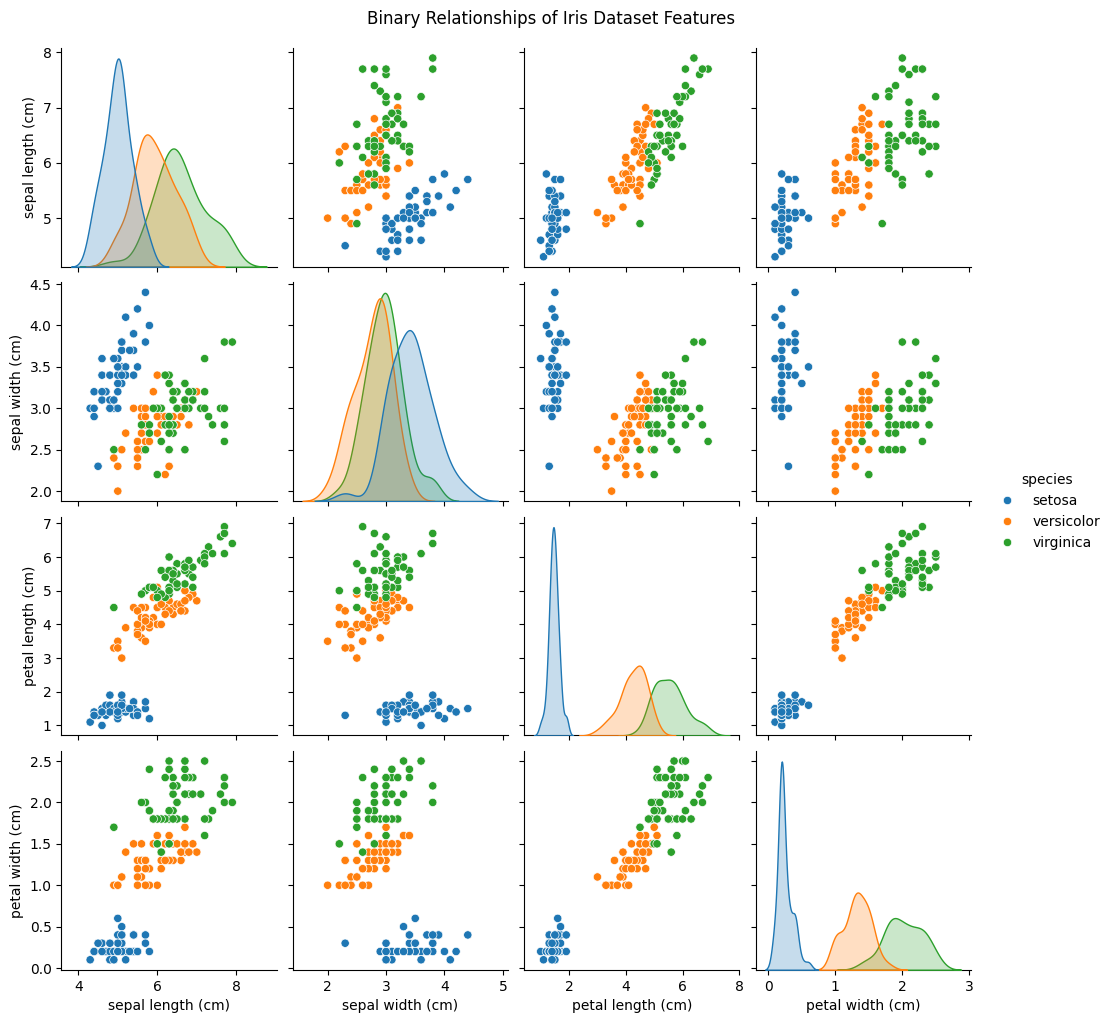

In [115]:
df_full_iris = pd.DataFrame(data=X_full, columns=iris.feature_names)
df_full_iris['species'] = iris.target_names[y_full]
sns.pairplot(df_full_iris, hue='species', diag_kind='kde')
plt.suptitle('Binary Relationships of Iris Dataset Features', y=1.02)
plt.show()

***Petal Width and Petal Length*** **are best features to separete accardoring to us**

**Label names. Data has 3 label:** ***Setosa, Versicolor, Virginica***

In [116]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

## Split the data

***X_train_full and X_test full*** **are [105X4] matrices with 4 features.** ***X-train_2f and X_test_2f*** **are [105X2] matrices with 2 feature**
This for we can need both type of data

In [117]:


# 4 Feature raw data train-test split
X_train_full, X_test_full, y_train, y_test = train_test_split(X_full, y_full, 
                                                              test_size=0.3, 
                                                              random_state=42, 
                                                              stratify=y_full)

X_train_2f = X_train_full[:, [2, 3]]
X_test_2f = X_test_full[:, [2, 3]]

X_full.shape




(150, 4)

**Standardization (scaling) is applied to the features before training the models.**

StandardScaler transforms the features to have zero mean and unit variance, which helps many machine learning algorithms perform better. Here, both the 2-feature and full-feature datasets are scaled separately for training and test sets.

In [118]:
scaler_2f = StandardScaler()
# Only fit on training data
X_train_2f_scaled = scaler_2f.fit_transform(X_train_2f)

# Transform test data with the fitted scaler
X_test_2f_scaled = scaler_2f.transform(X_test_2f)


# Full feature set scaling
scaler_full = StandardScaler()
X_train_scaled = scaler_full.fit_transform(X_train_full)
X_test_scaled = scaler_full.transform(X_test_full)

**This function visualizes the decision boundaries of a classifier.**

It creates a mesh grid over the feature space, predicts the class for each point, and colors the regions according to the predicted class. The actual data points are plotted on top for comparison. This helps to visually assess how well the model separates different classes.

In [119]:
def plot_decision_boundary(X, y, model, title):
    """
    Visualize the decision boundaries of a classifier.
    """
    # Set color maps and markers
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ['red', 'green', 'blue']

    # Set step size
    h = .02  # step size in the mesh

    # Find the min and max values of the features and leave some margin
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # Create a mesh grid
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Make predictions for each point in the grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    # Reshape the result back to the grid shape
    Z = Z.reshape(xx.shape)

    # Plot the graph
    plt.figure(figsize=(10, 8))
    # Color the decision boundaries
    plt.contourf(xx, yy, Z, cmap=cmap_light)

    # Draw the training points on top
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=iris.target_names[y],
                    palette=cmap_bold, alpha=1.0, edgecolor="black")
    
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.xlabel('Petal Length (cm)')
    plt.ylabel('Petal Width (cm)')
    plt.legend(title='Species')
    plt.show()



## Part 2: From-Scratch Implementation
## Part 2.1 Single Layer Perceptron

**SingleLayerPerceptron Class**

This class implements a basic single-layer perceptron (SLP) for binary classification tasks. It uses a linear decision boundary and the perceptron learning rule for weight updates.

**Parameters:**
- `learning_rate` (float): Step size for weight updates (default: 0.01)
- `n_iters` (int): Number of training epochs (default: 1000)
- `random_state` (int): Seed for random weight initialization (default: 42)

**Main Methods:**
- `fit(X, y)`: Trains the perceptron on input features `X` and labels `y`.
- `predict(X)`: Predicts class labels for input features `X`.

The perceptron applies a unit step function to the linear combination of inputs and weights.

In [120]:
class SingleLayerPerceptron:
    """Single Layer Perceptron (SLP) classifier."""
    def __init__(self, learning_rate=0.01, n_iters=1000, random_state=42):
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.random_state = random_state
        self.weights_ = None
        self.errors_ = []
        #Weights initialization moved to fit method.

   

    def fit(self, X, y, plot_every=None): #plot_every may be called from OvR
        """Fits the model to the training data."""
        
        
        rgen = np.random.RandomState(self.random_state)
        # init weights according to X shape
        if self.weights_ is None: 
            self.weights_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1] + 1) 
        # --------------------------------------------------------

        self.errors_ = []
        for epoch in range(self.n_iters):
            self.train_epoch(X, y) 
            
        return self

    # train_epoch method
    def train_epoch(self, X, y):
        """One epoch of training."""
        X_b = np.c_[np.ones((len(X), 1)), X]
        errors = 0
        for xi, target in zip(X_b, y):
            # predict(xi) calls net_input(xi), which calls np.dot(xi, self.weights_)
            # now self.weights_ should be of correct shape (3,)
            update = self.learning_rate * (target - self.predict(xi)) 
            self.weights_ += update * xi
            errors += int(update != 0.0)
        self.errors_.append(errors)
        
    # net_input method
    def net_input(self, X):
        """Calculates net input."""
        if X.ndim == 2:
             X_b = np.c_[np.ones((len(X), 1)), X]
             # np.dot(X_b [N, 3], self.weights_ [3,])
             return np.dot(X_b, self.weights_)
        else: # Single sample (xi, shape is (3,))
             # np.dot(X [3,], self.weights_ [3,]) 
             return np.dot(X, self.weights_)

    # predict method
    def predict(self, X):
        """Makes a prediction (unit step function)."""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

**SLP_OvR Class**

This class implements the One-vs-Rest (OvR) strategy for multi-class classification using multiple single-layer perceptrons (SLP). Each perceptron is trained to distinguish one class from all others.

**Parameters:**
- `n_classes` (int): Number of unique classes in the dataset
- `learning_rate` (float): Step size for weight updates (default: 0.01)
- `n_iters` (int): Number of training epochs for each perceptron (default: 100)
- `random_state` (int): Seed for random weight initialization (default: 42)

**Main Methods:**
- `fit(X, y, plot_every=5)`: Trains one perceptron per class in a one-vs-rest manner
- `predict(X)`: Predicts class labels for input features `X` by selecting the perceptron with the highest activation

This approach allows extension of binary SLPs to multi-class problems.

In [121]:
class SLP_OvR:
    def __init__(self, n_classes, learning_rate=0.01, n_iters=100, random_state=42): # We can set default n_iters lower for OvR
        self.n_classes = n_classes
        self.learning_rate = learning_rate
        self.n_iters = n_iters # iteration count for SLP
        self.random_state = random_state
        self.perceptrons_ = [
            # n_iters for SLP not for OvR
            SingleLayerPerceptron(learning_rate=self.learning_rate, n_iters=1, random_state=self.random_state + i) 
            #every single perceptron gets different seed
            for i in range(self.n_classes)
        ]


    
    def fit(self, X, y, plot_every=5):
        """
        Train each perceptron in a one-vs-rest manner.
        """
        n_features = X.shape[1] # Get number of features

        # Initialize weights to the correct shape from the start (without waiting for SLP.fit)
        for p in self.perceptrons_:
            if p.weights_ is None:
                 rgen = np.random.RandomState(p.random_state)
                 p.weights_ = rgen.normal(loc=0.0, scale=0.01, size=n_features + 1)

        # Epoch
        for epoch in range(self.n_iters): # This for Epoch for OvR
            for i in range(self.n_classes):
                y_ovr = np.where(y == i, 1, 0)
                # Since SLP has n_iters=1 this only runs one epoch
                self.perceptrons_[i].train_epoch(X, y_ovr) 
            
            if (epoch + 1) % plot_every == 0:
                print(f"--- Epoch {epoch + 1} ---")
                plot_decision_boundary(X, y, self,
                                       title=f'SLP Decision Boundaries - Epoch {epoch + 1}')
        return self

    # predict method can remain the same
    def predict(self, X):
        """
        Return the class of the perceptron with the highest activation value as the prediction.
        """
        activations = np.array([p.net_input(X) for p in self.perceptrons_])
        return np.argmax(activations, axis=0)

**Run the Single Layer Perceptron and plot Decision Boundry every 5 epoch**

--- Epoch 5 ---


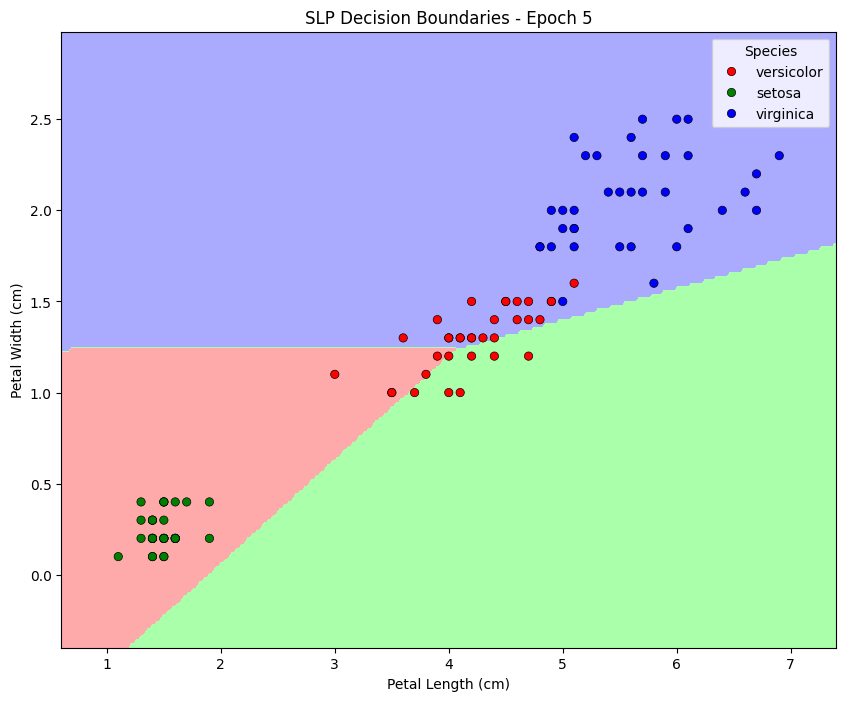

--- Epoch 10 ---


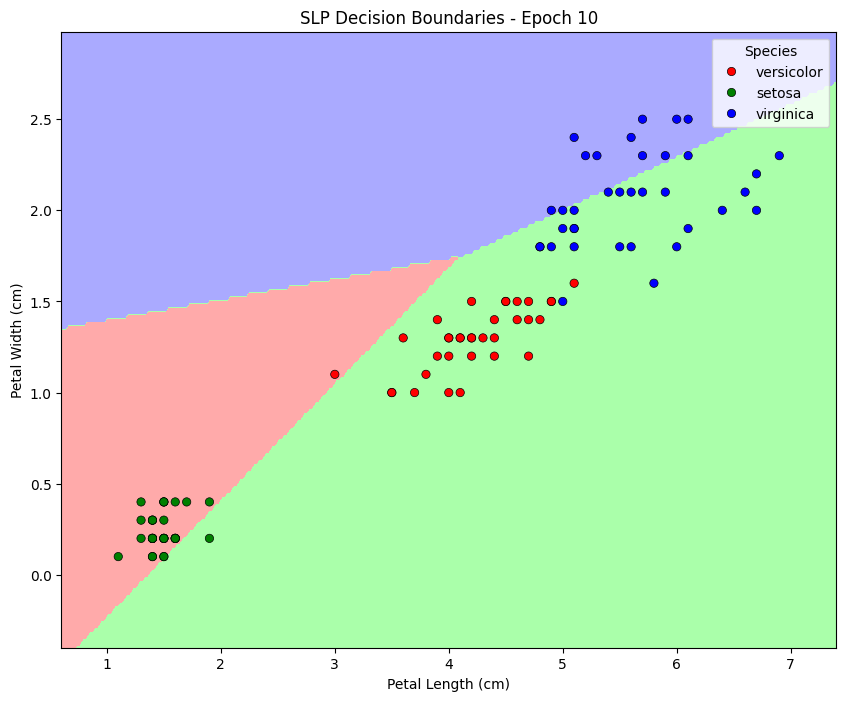

--- Epoch 15 ---


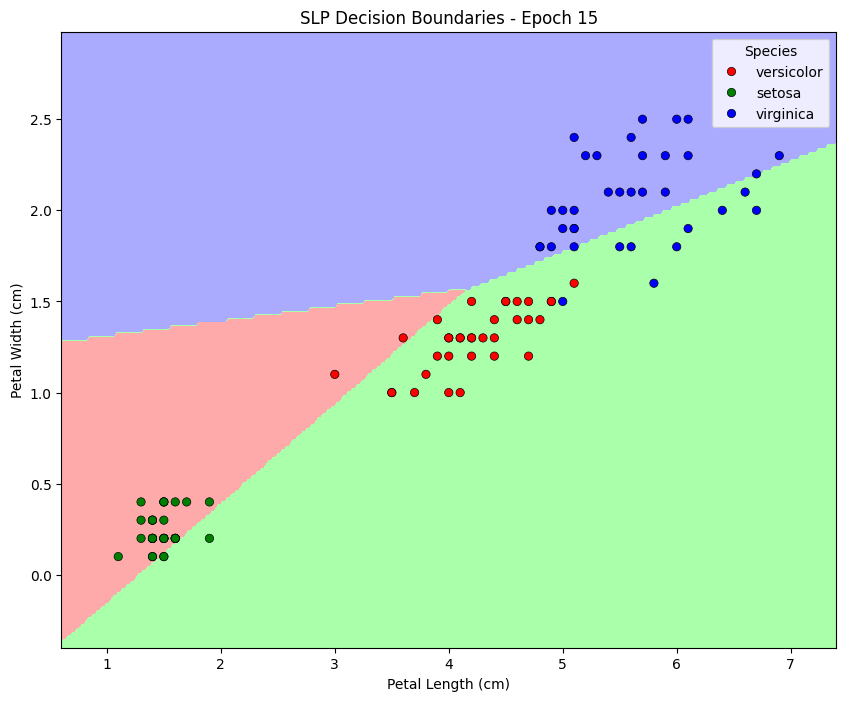

--- Epoch 20 ---


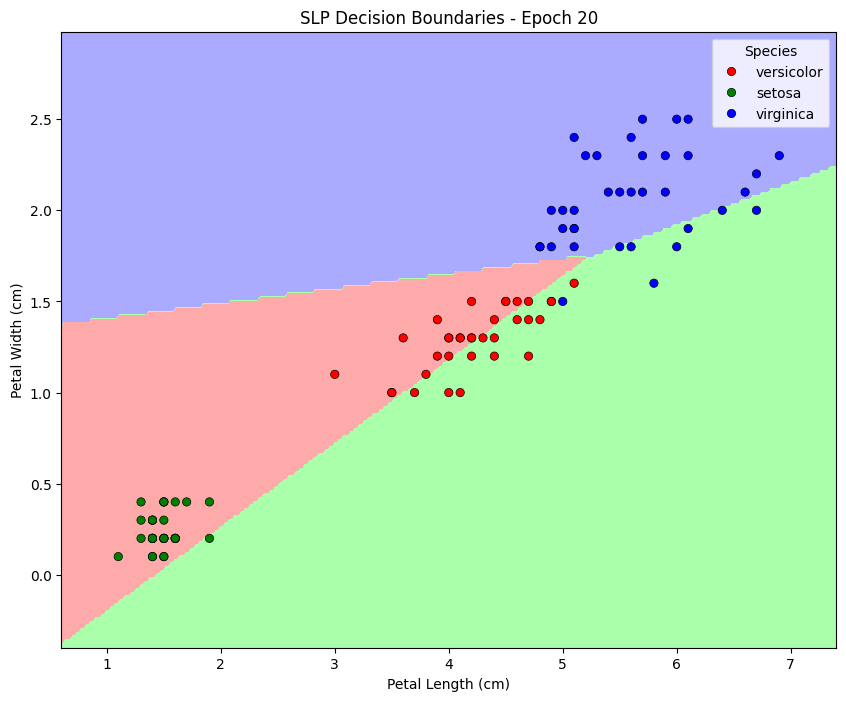

--- Epoch 25 ---


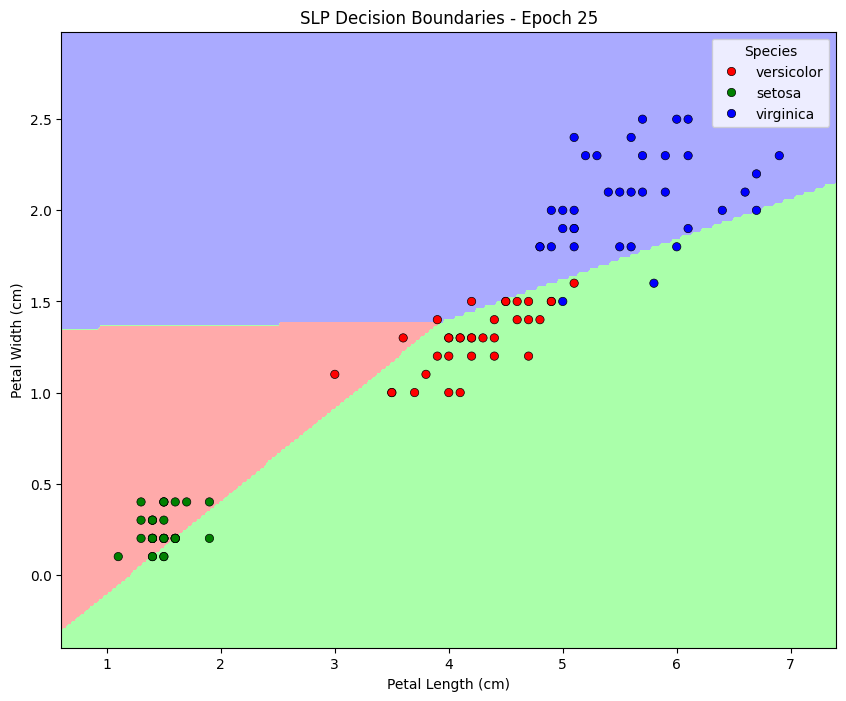

--- Epoch 30 ---


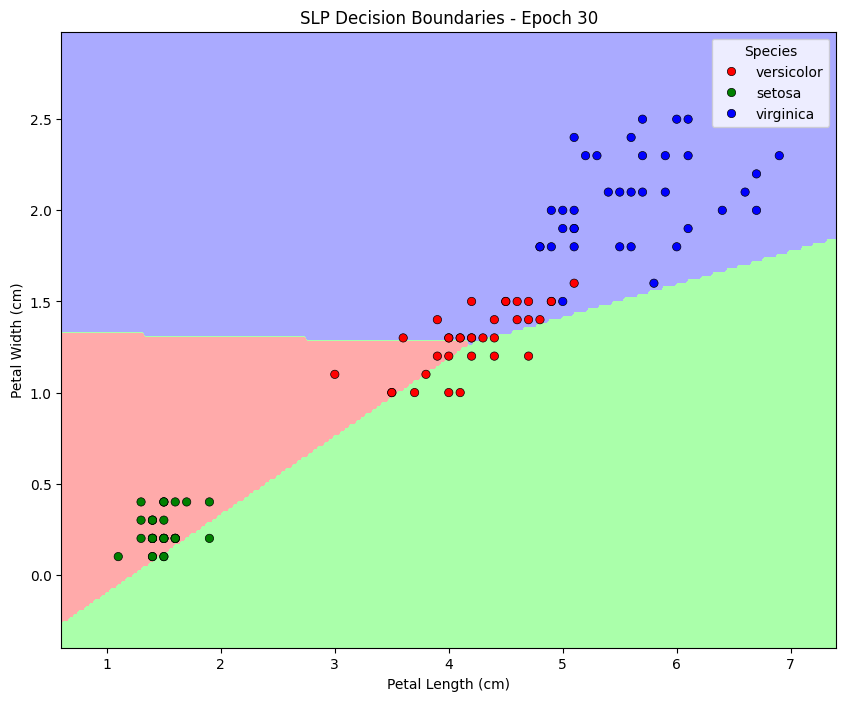

--- Epoch 35 ---


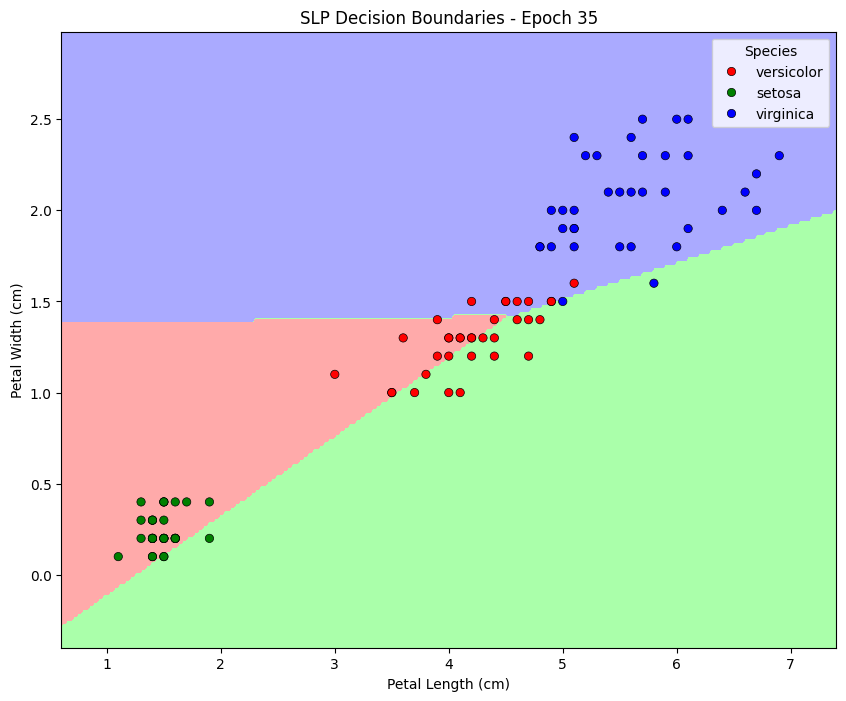

--- Epoch 40 ---


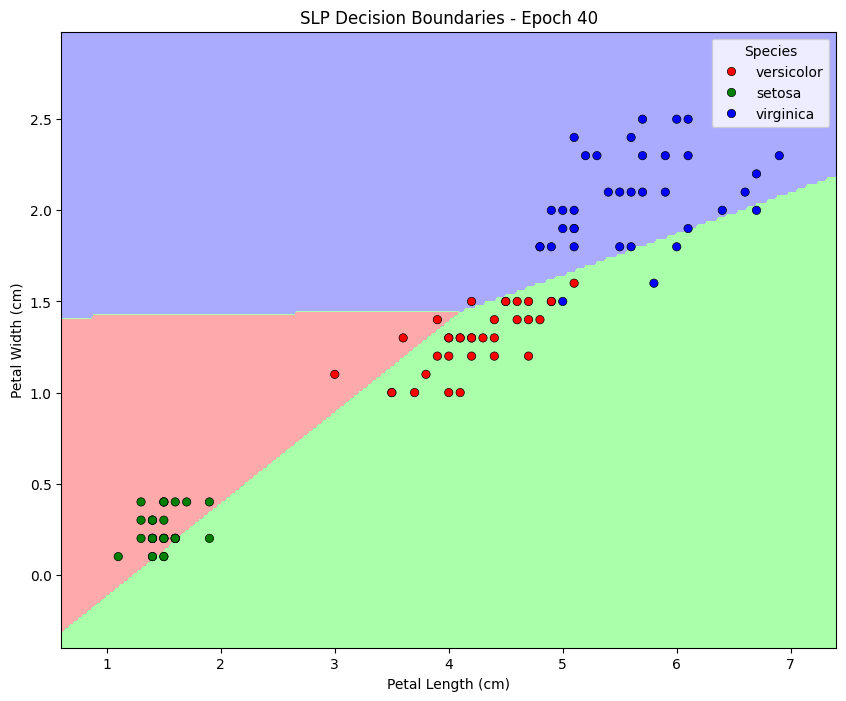

--- Epoch 45 ---


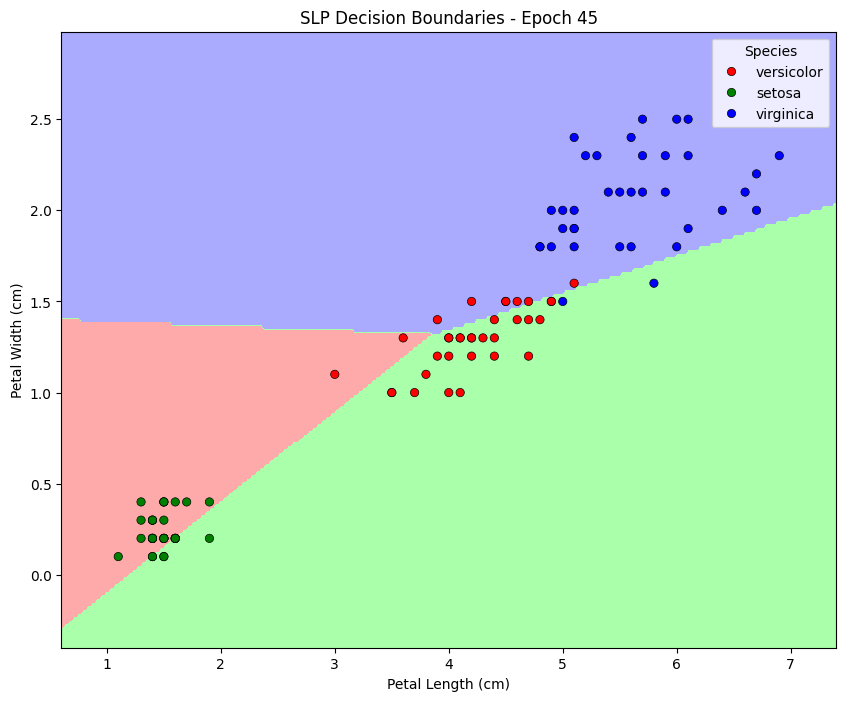

--- Epoch 50 ---


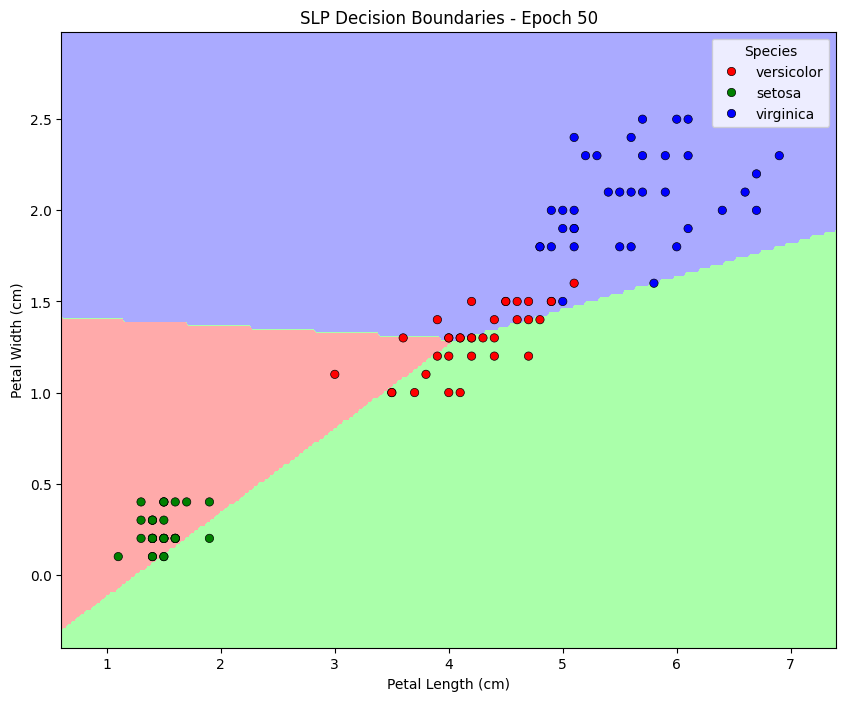

--- Epoch 55 ---


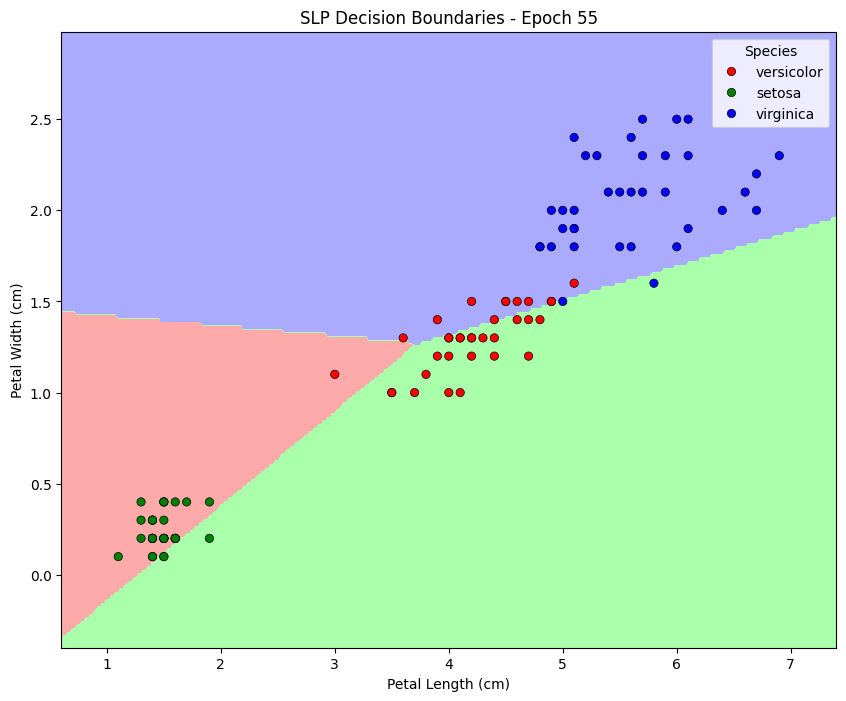

--- Epoch 60 ---


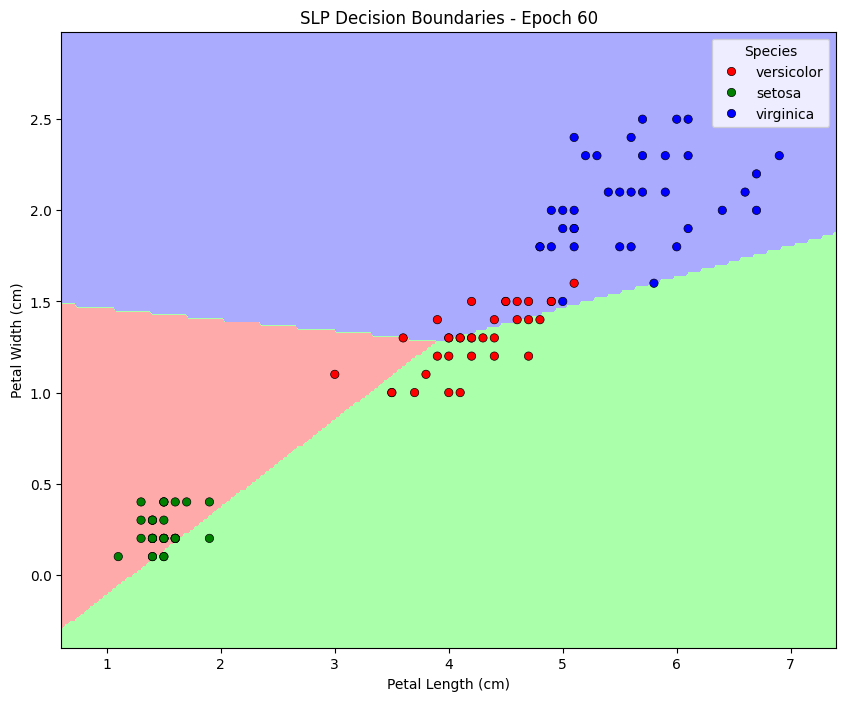

--- Epoch 65 ---


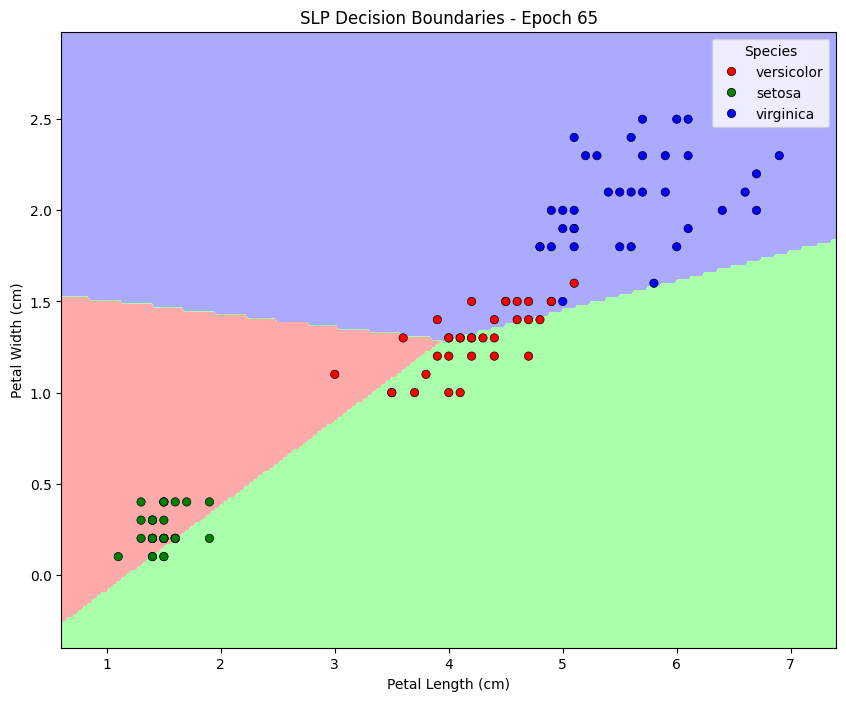

--- Epoch 70 ---


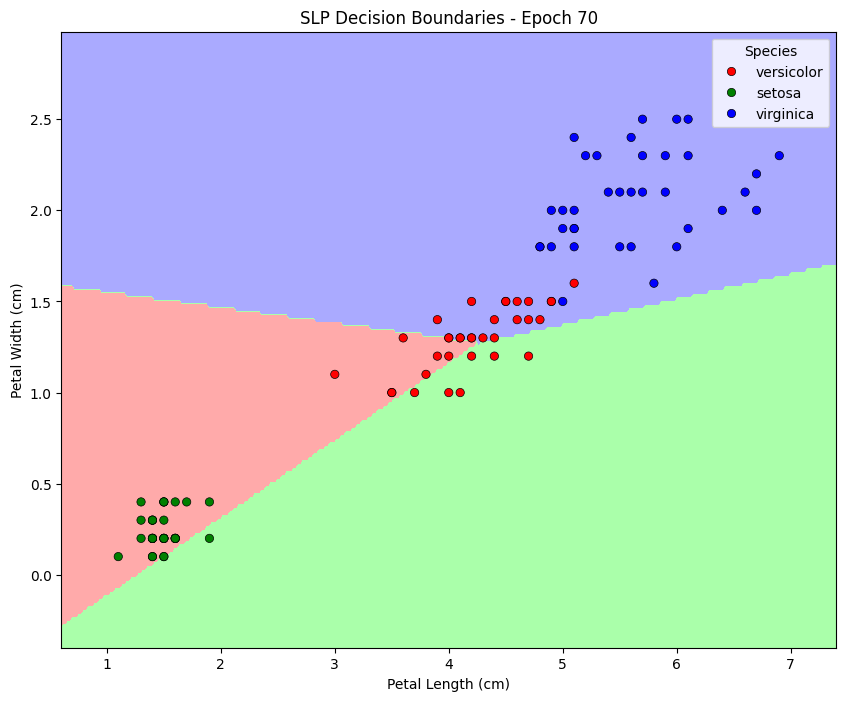

--- Epoch 75 ---


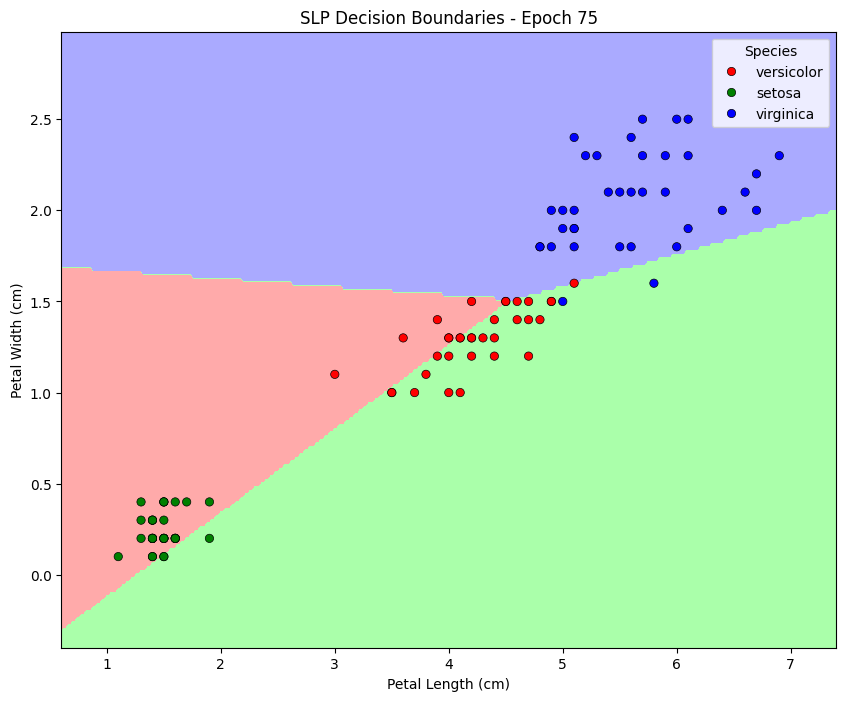

--- Epoch 80 ---


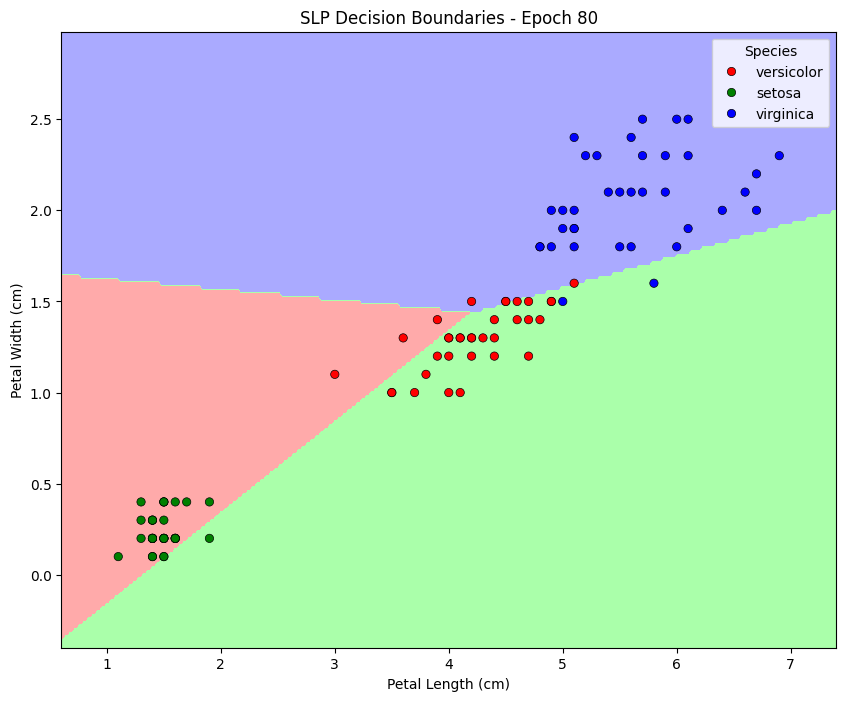

--- Epoch 85 ---


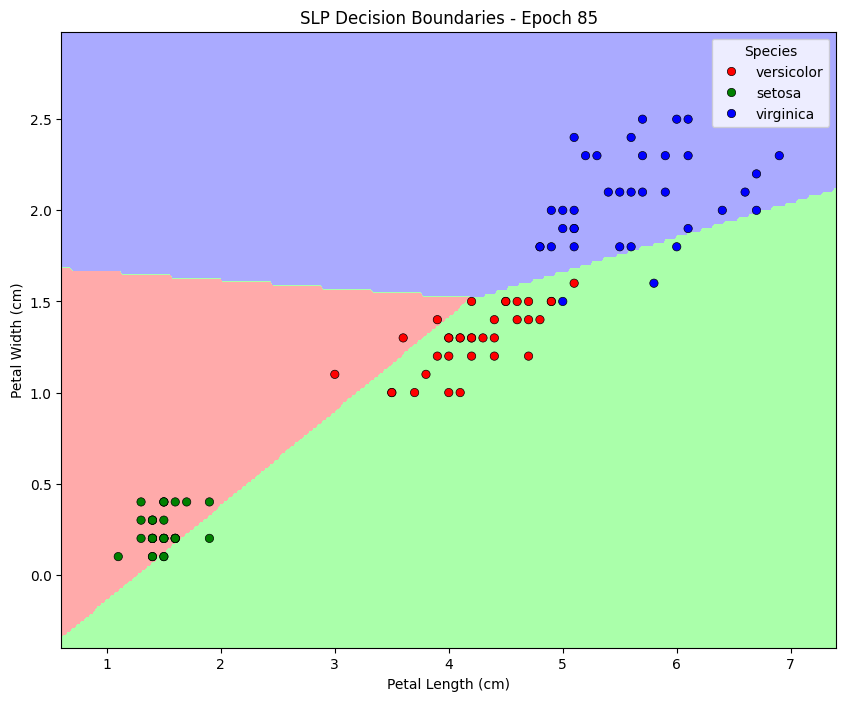

--- Epoch 90 ---


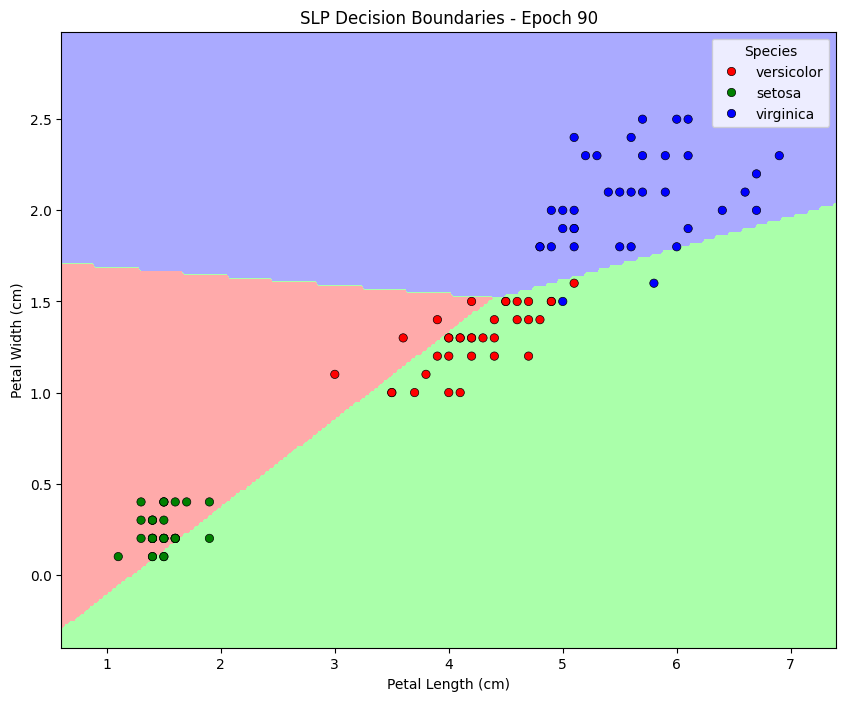

--- Epoch 95 ---


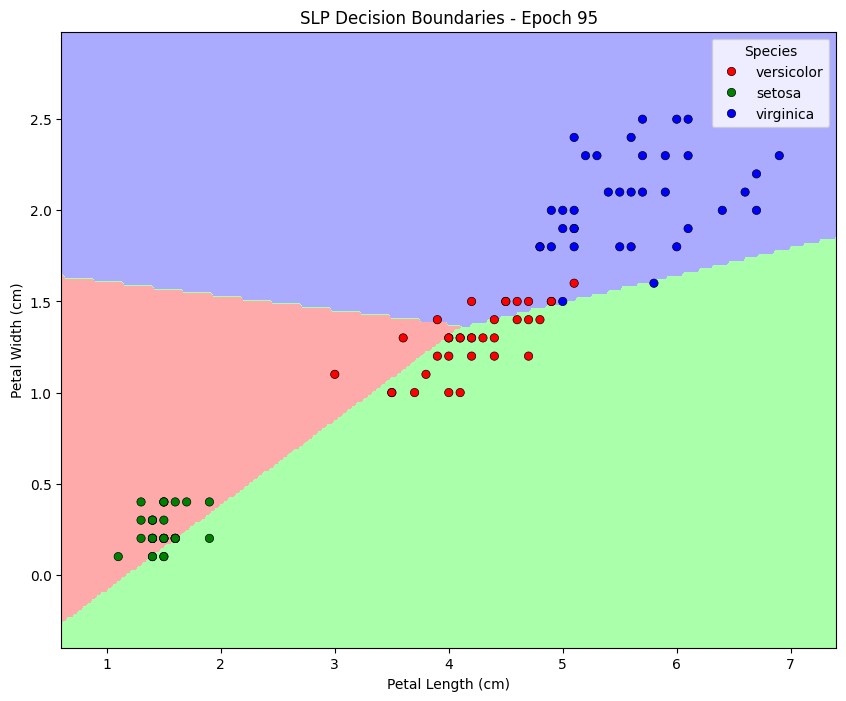

--- Epoch 100 ---


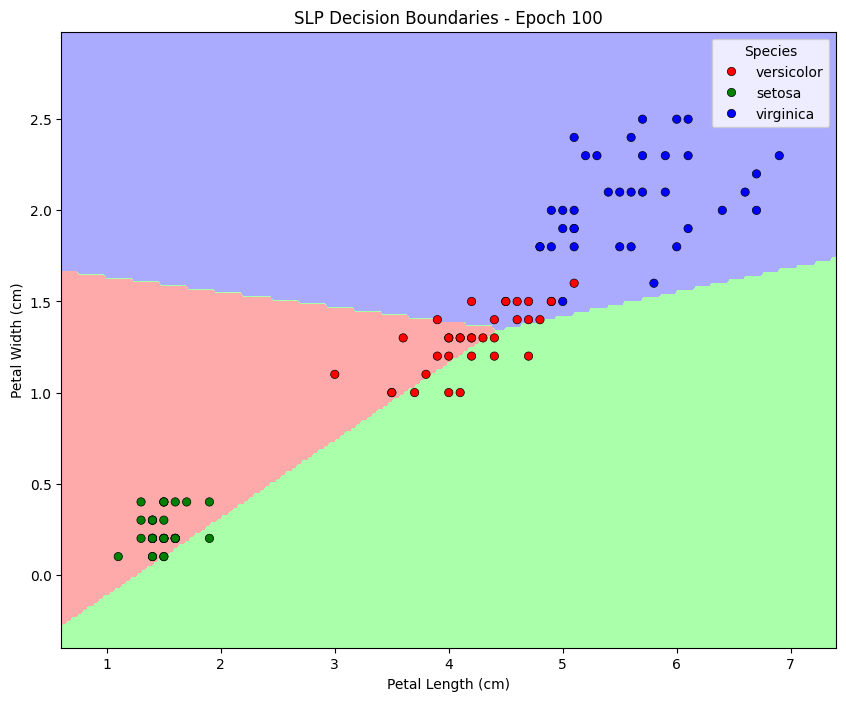

--- Epoch 105 ---


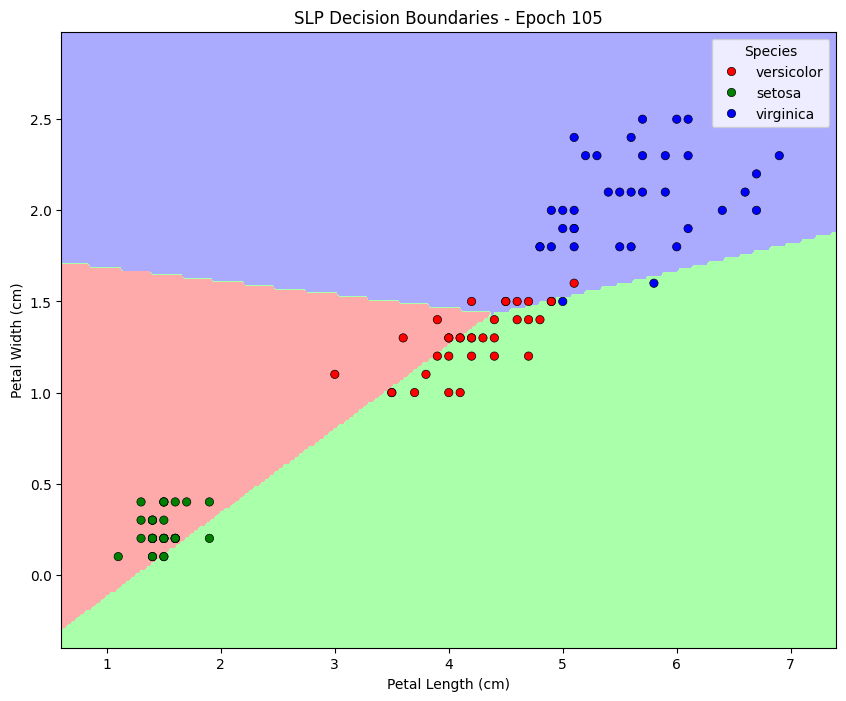

--- Epoch 110 ---


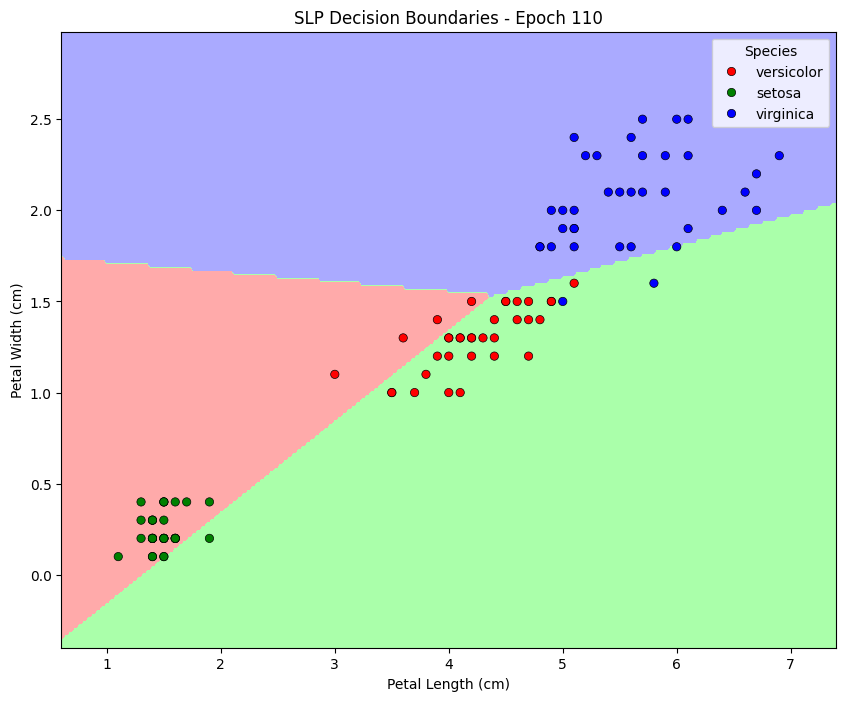

--- Epoch 115 ---


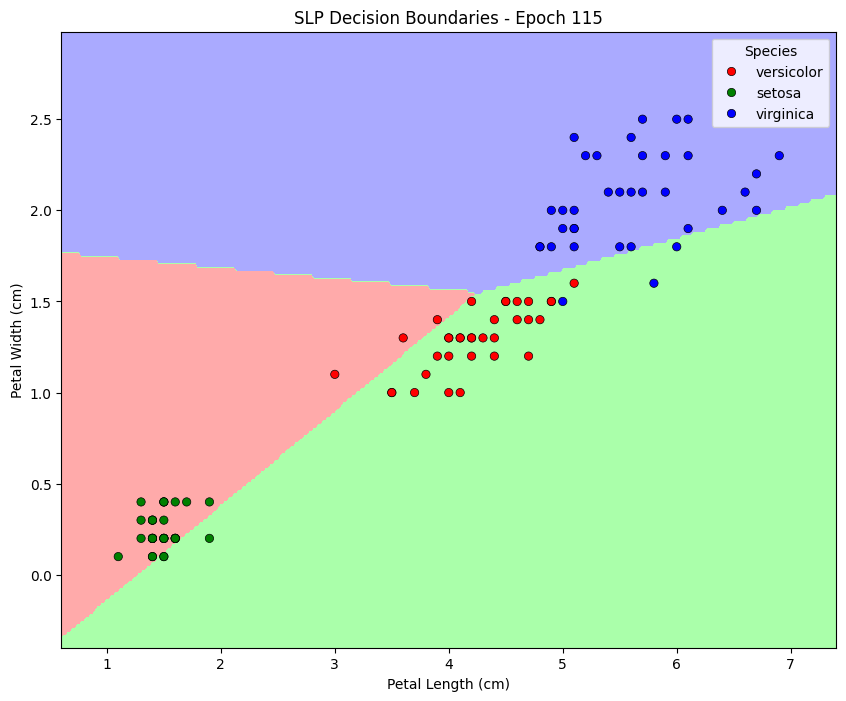

--- Epoch 120 ---


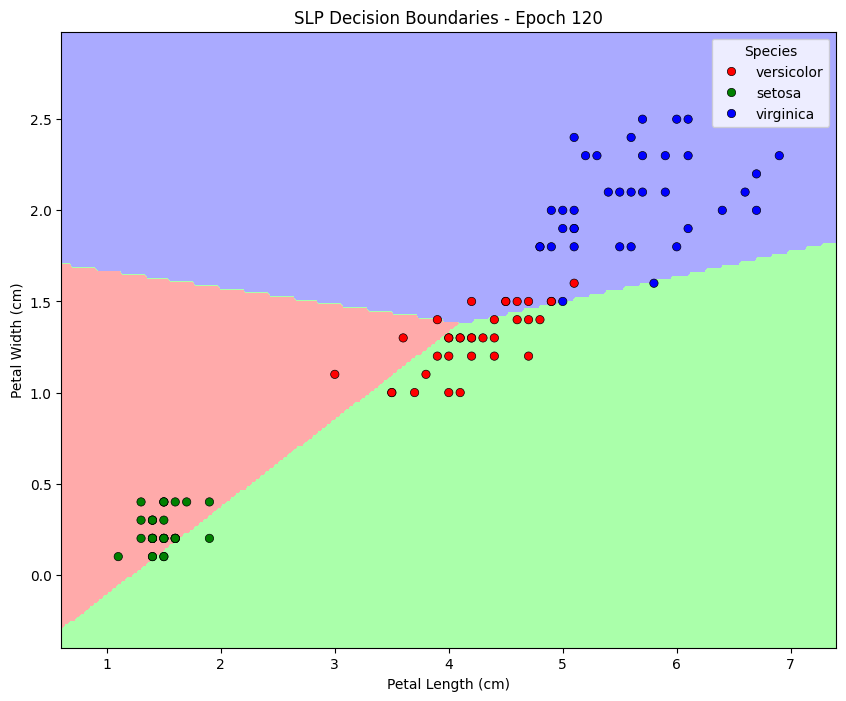

--- Epoch 125 ---


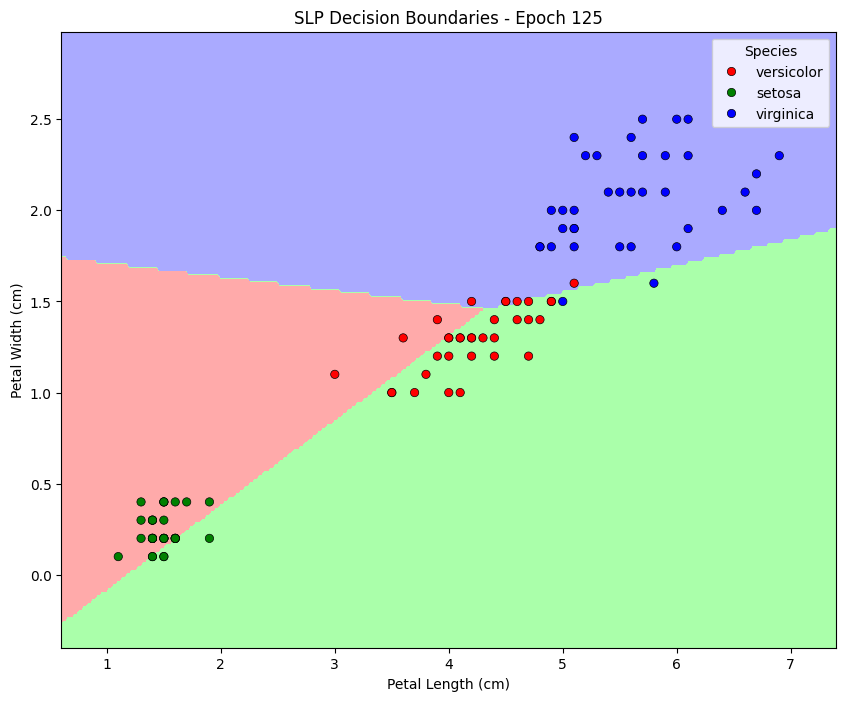

--- Epoch 130 ---


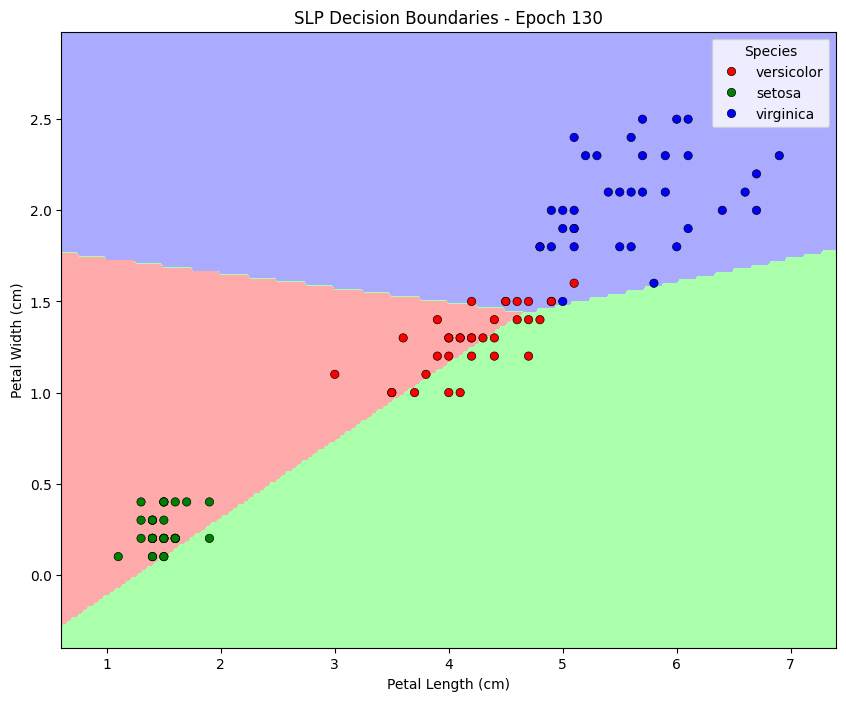

--- Epoch 135 ---


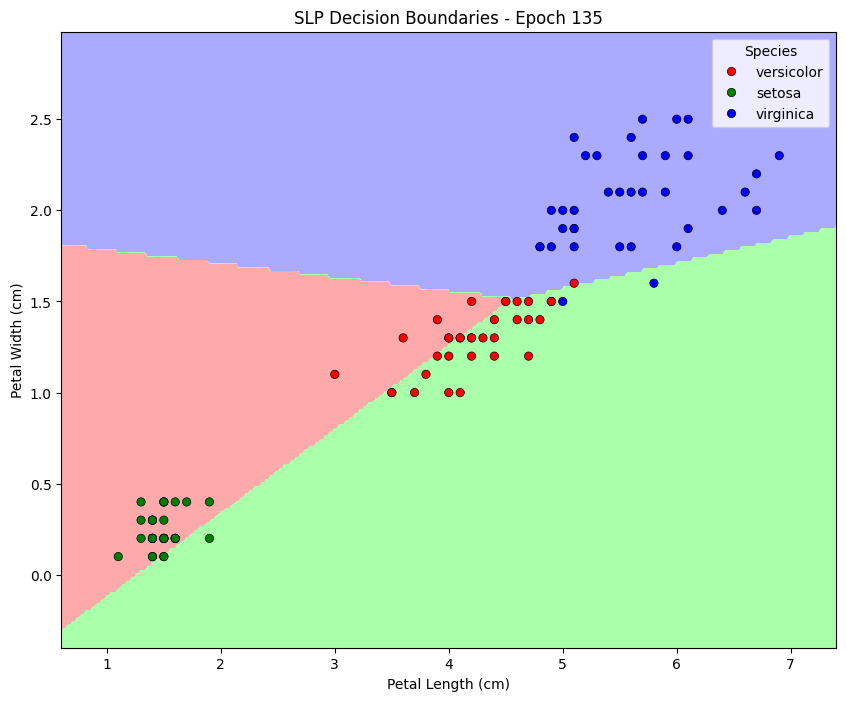

--- Epoch 140 ---


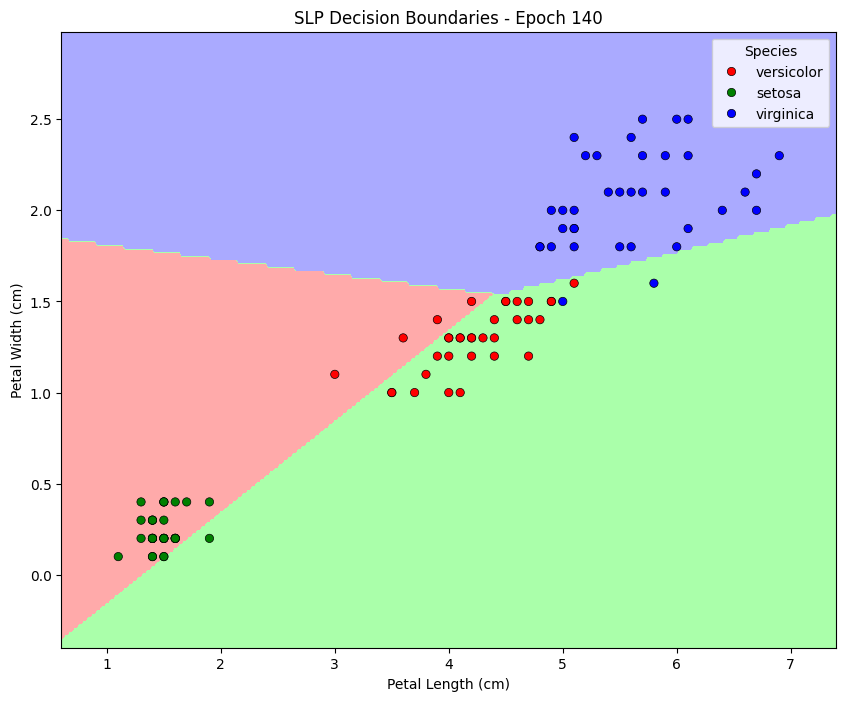

--- Epoch 145 ---


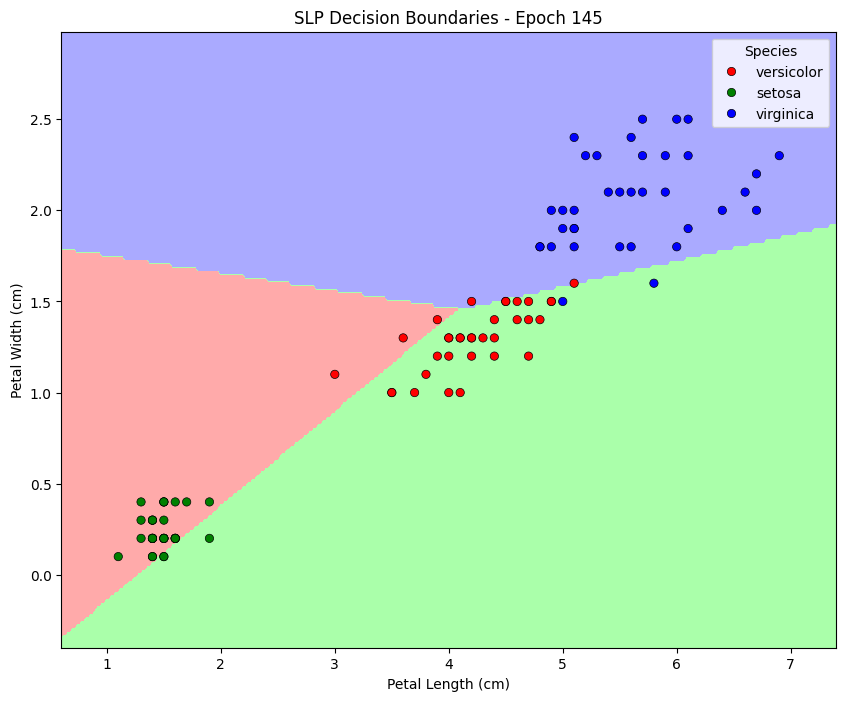

--- Epoch 150 ---


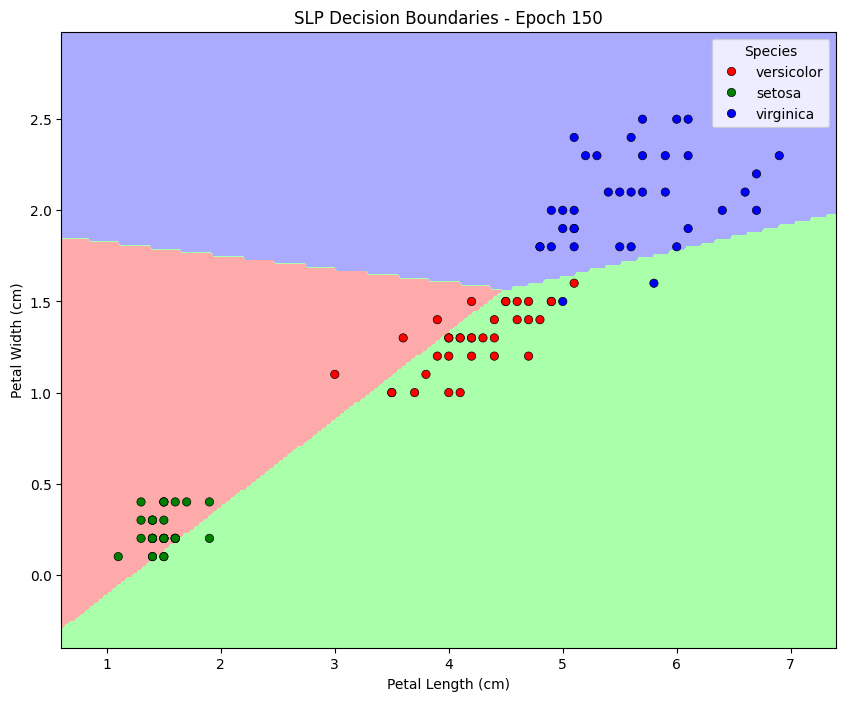

--- Epoch 155 ---


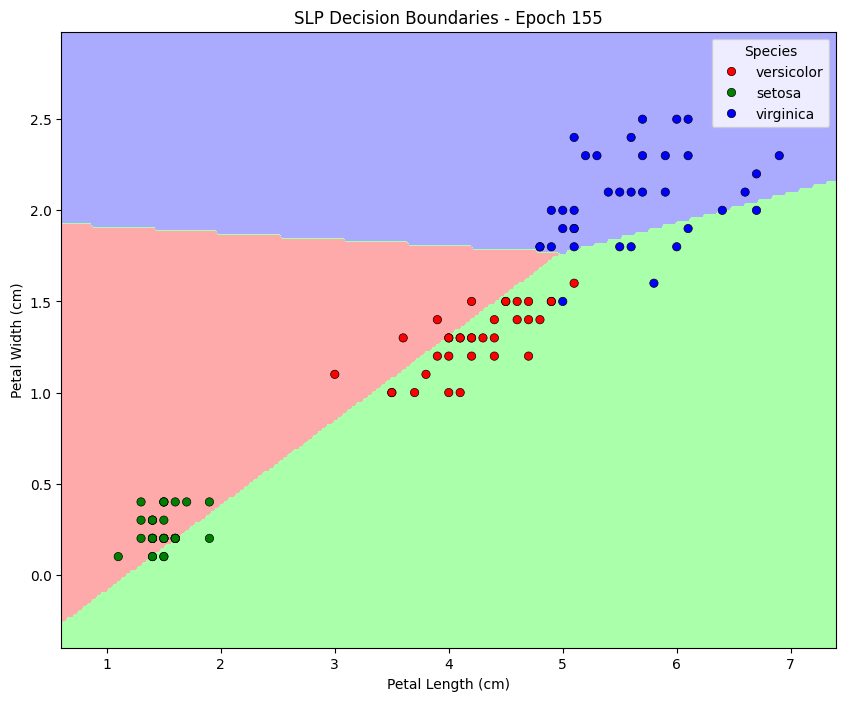

--- Epoch 160 ---


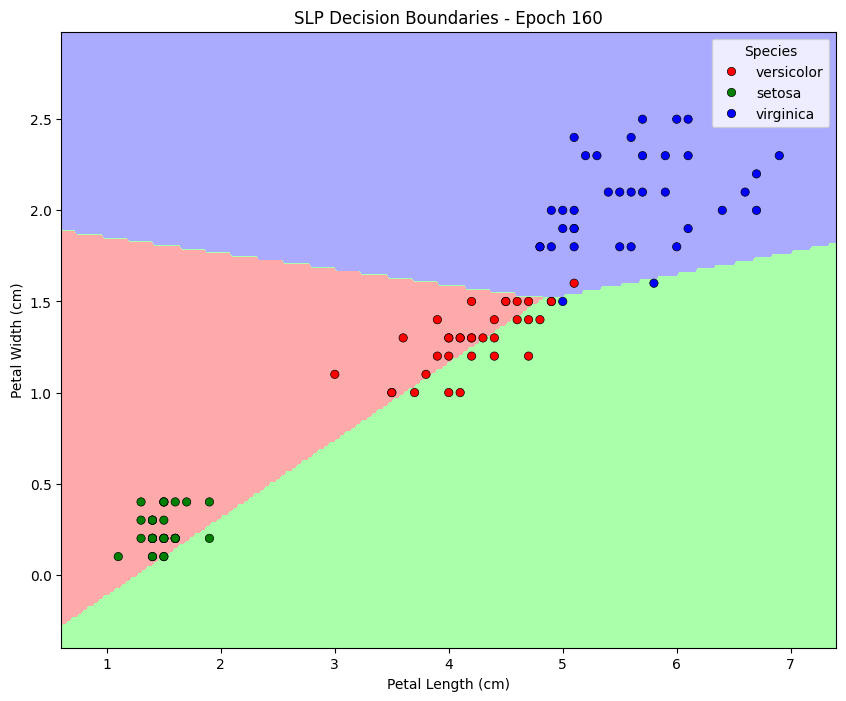

--- Epoch 165 ---


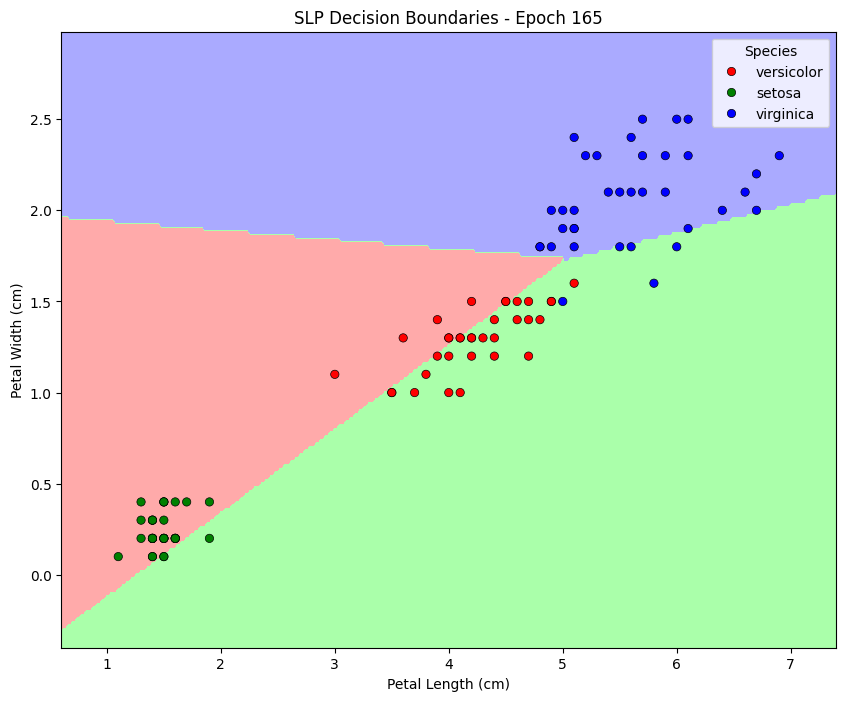

--- Epoch 170 ---


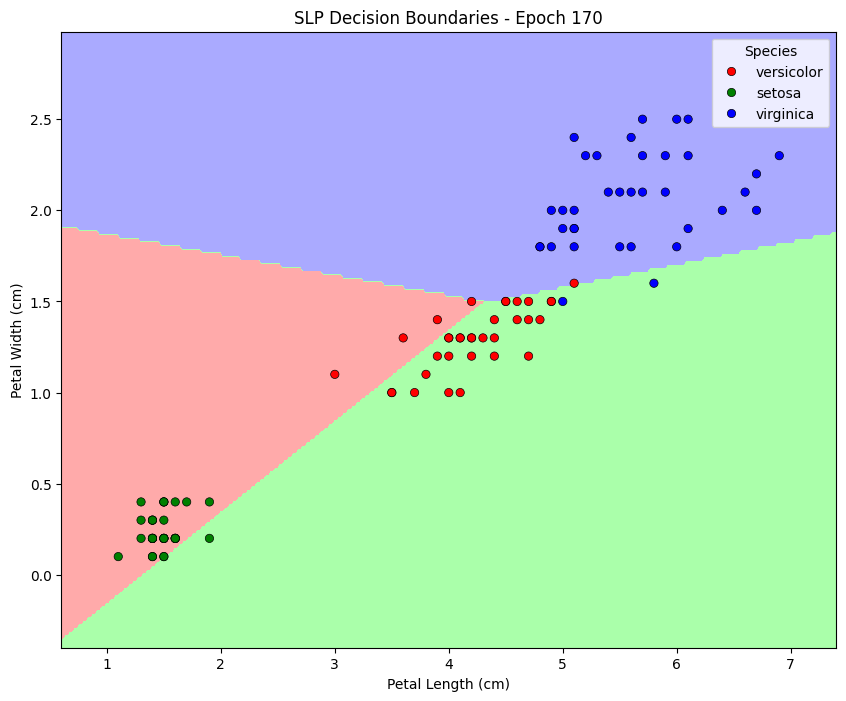

--- Epoch 175 ---


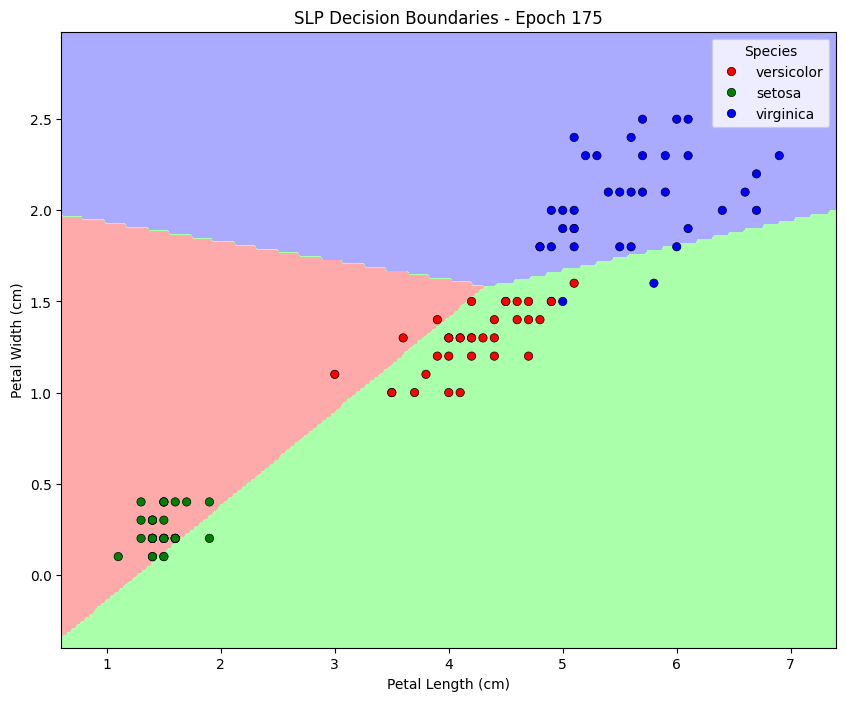

In [122]:
n_classes = len(np.unique(y_full))

# Create OvR model
slp_ovr_model = SLP_OvR(n_classes=n_classes, learning_rate=0.01, n_iters=175, random_state=42)

# Train the model
slp_ovr_model.fit(X_train_2f, y_train, plot_every=5)

In [123]:
y_pred = slp_ovr_model.predict(X_test_2f)


Model Test Accuracy: 0.89

Classification Report:


```
              precision    recall  f1-score   support

           0       1.00      0.93      0.97        15
           1       0.78      0.93      0.85        15
           2       0.92      0.80      0.86        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45

```


Confusion Matrix:


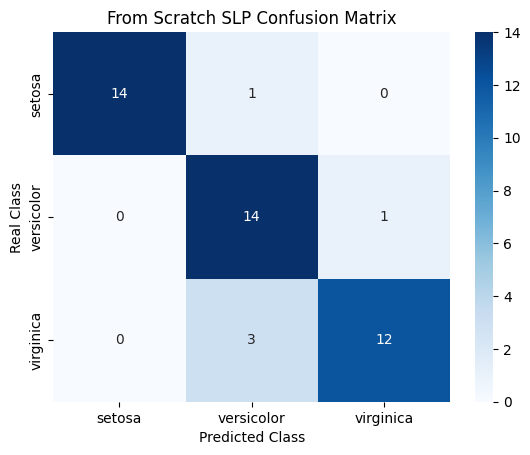

In [124]:
# evaluate results
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Test Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
report = classification_report(y_test, y_pred)
display(Markdown(f"```\n{report}\n```")) # [cite: 22]
print("\nConfusion Matrix:") # [cite: 22]
#print(confusion_matrix(y_test, y_pred))



#print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted Class')
plt.ylabel('Real Class')
plt.title('From Scratch SLP Confusion Matrix')
plt.show()

### SLP_OvR Test Accuracies for Different Learning Rates and Epoch Numbers

| Learning Rate (LR) | Epoch            | Accuracy                 |
|:------------------:|:----------------:|:-------------------------:|
| 0.1                | 100              | 0.78                      |
| 0.01               | 150              | 0.82                      |
| 0.01               | 200              | 0.84                      |
| 0.01               | 500              | 0.87                      |

This table shows the test accuracies achieved by the SLP_OvR model with different learning rates and epochs. A high learning rate (0.1) yields lower accuracy in a short time, while a lower learning rate (0.01) and more epochs increase the model's accuracy. These results demonstrate that the model generalizes better when trained for a sufficiently long time and with an appropriate learning rate.

## Part 2.2 Multi Layer Perceptron



The `MLPClassifierFromScratch` class below implements a simple Multi-Layer Perceptron (MLP) with one hidden layer using only NumPy. It supports multi-class classification, uses ReLU activation in the hidden layer and softmax in the output layer, and is trained with stochastic gradient descent and backpropagation. This implementation is for educational purposes and does not include advanced features such as regularization, batch training, or early stopping.

In [125]:


class MLPClassifierFromScratch:
    """
    Single Hidden Layer Multi-Layer Perceptron (MLP) Classifier from scratch using NumPy.
    1 hidden layer with tanh activation and softmax output layer.
    Uses Stochastic Gradient Descent (SGD) and backpropagation for training.
    """
    def __init__(self, n_hidden=10, learning_rate=0.1, n_iters=2000, random_state=42):
        self.n_hidden = n_hidden          # Neurons in hidden layer
        self.lr = learning_rate           # Learning rate
        self.n_iters = n_iters            # Number of epochs
        self.random_state = random_state  # For reproducibility
        self.weights1 = None              # Input -> Hidden layer weights
        self.bias1 = None                 # Hidden layer bias
        self.weights2 = None              # Hidden layer -> Output weights
        self.bias2 = None                 # Output layer bias

    def _tanh(self, x):
        return np.tanh(x)

    def _tanh_derivative(self, x):
        return 1 - np.tanh(x)**2
    
    def _relu(self, x):
        return np.maximum(0, x)

    def _relu_derivative(self, x):
        return np.where(x > 0, 1, 0)

    def _softmax(self, z):
        # For numerical stability, we subtract the max value from z.
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def fit(self, X, y, plot_every=5):
        """Train the model."""
        n_samples, n_features = X.shape
        n_outputs = len(np.unique(y))

        # Initialize weights and biases randomly
        np.random.seed(self.random_state)
        self.weights1 = np.random.randn(n_features, self.n_hidden) * 0.01
        self.bias1 = np.zeros((1, self.n_hidden))
        self.weights2 = np.random.randn(self.n_hidden, n_outputs) * 0.01
        self.bias2 = np.zeros((1, n_outputs))

        # One-hot encoding for y
        y_one_hot = np.zeros((n_samples, n_outputs))
        y_one_hot[np.arange(n_samples), y] = 1

        # SGD Training Loop
        for epoch in range(self.n_iters):
            # Shuffle the data at each epoch (Stochastic property)
            indices = np.random.permutation(n_samples)
            X_shuffled = X[indices]
            y_shuffled_one_hot = y_one_hot[indices]

            for i in range(n_samples):
                xi = X_shuffled[i:i+1]
                yi = y_shuffled_one_hot[i:i+1]

                # 1. Forward Propagation
                # Input -> Hidden Layer
                z1 = np.dot(xi, self.weights1) + self.bias1
                a1 = self._relu(z1)

                # Hidden -> Output Layer
                z2 = np.dot(a1, self.weights2) + self.bias2
                y_pred_proba = self._softmax(z2)

                # 2. Backpropagation
                # Output layer error
                delta2 = y_pred_proba - yi

                # Hidden layer error
                d_z1 = self._relu_derivative(z1)
                delta1 = np.dot(delta2, self.weights2.T) * d_z1

                # 3. Weight and Bias Updates
                # Hidden -> Output weights
                self.weights2 -= self.lr * np.dot(a1.T, delta2)
                self.bias2 -= self.lr * np.sum(delta2, axis=0, keepdims=True)

                # Input -> Hidden weights
                self.weights1 -= self.lr * np.dot(xi.T, delta1)
                self.bias1 -= self.lr * np.sum(delta1, axis=0, keepdims=True)
            
            if (epoch + 1) % plot_every == 0:
                print(f"--- Epoch {epoch + 1} ---")
                plot_decision_boundary(X, y, self,
                                       title=f'mlp Decision Boundaries - Epoch {epoch + 1}')

    def predict_proba(self, X):
        """Predict class probabilities."""
        z1 = np.dot(X, self.weights1) + self.bias1
        a1 = self._relu(z1)
        z2 = np.dot(a1, self.weights2) + self.bias2
        return self._softmax(z2)

    def predict(self, X):
        """Predict class labels."""
        probas = self.predict_proba(X)
        return np.argmax(probas, axis=1)

**MLPClassifierFromScratch Evaluation**

The following code trains a custom Multi-Layer Perceptron (MLP) model from scratch using two features of the Iris dataset. After training, it evaluates the model's performance on the test set by printing the classification report and displaying the confusion matrix as a heatmap. This allows for a detailed analysis of the model's accuracy and class-wise prediction performance.

--- Epoch 5 ---


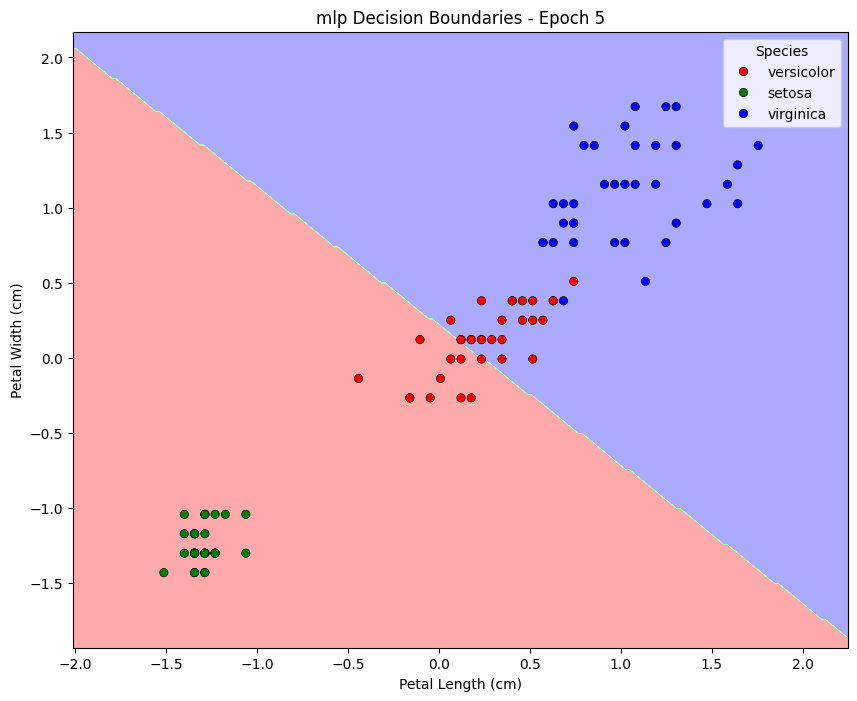

--- Epoch 10 ---


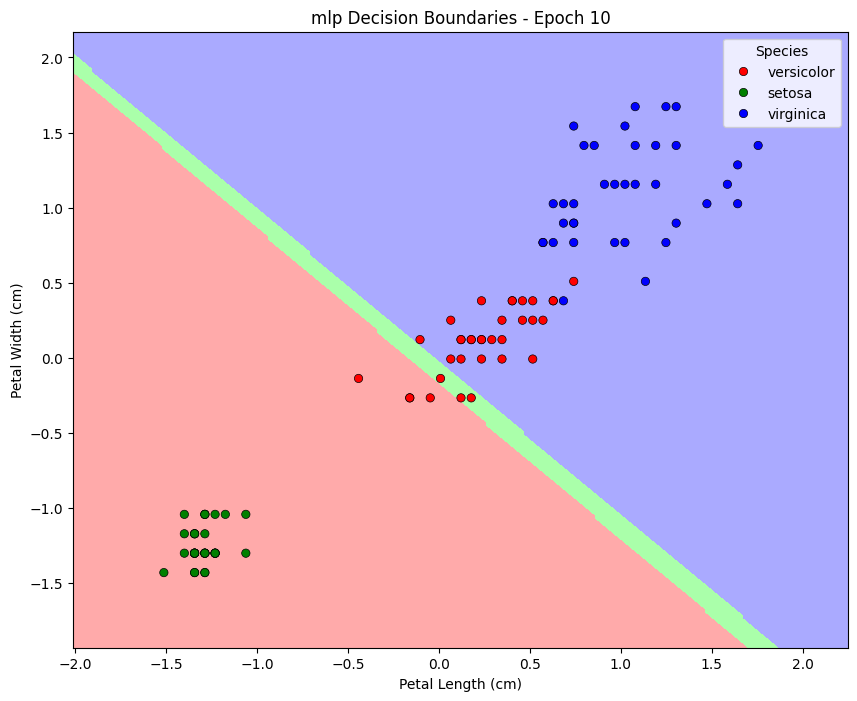

--- Epoch 15 ---


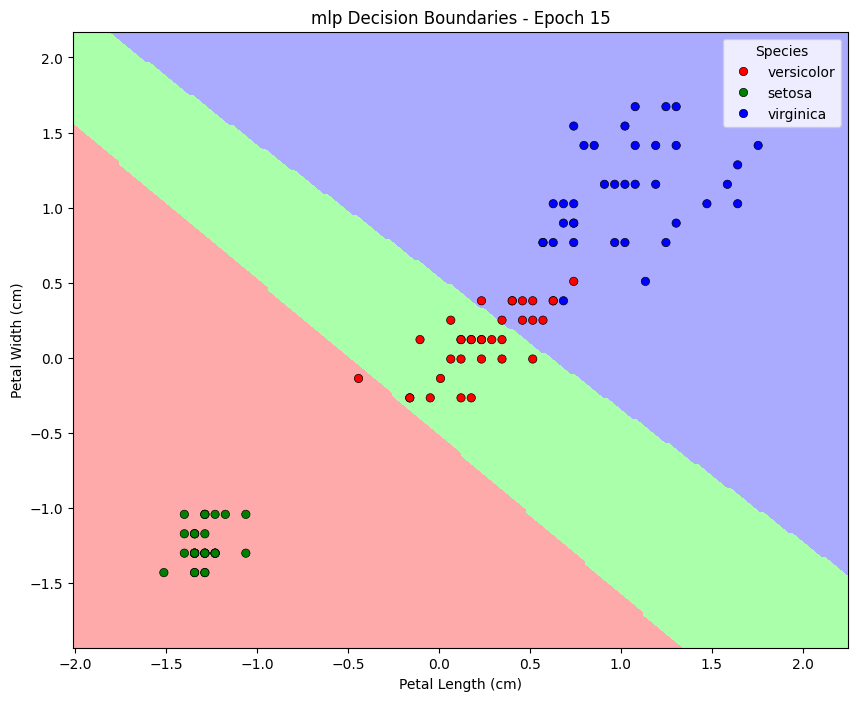

--- Epoch 20 ---


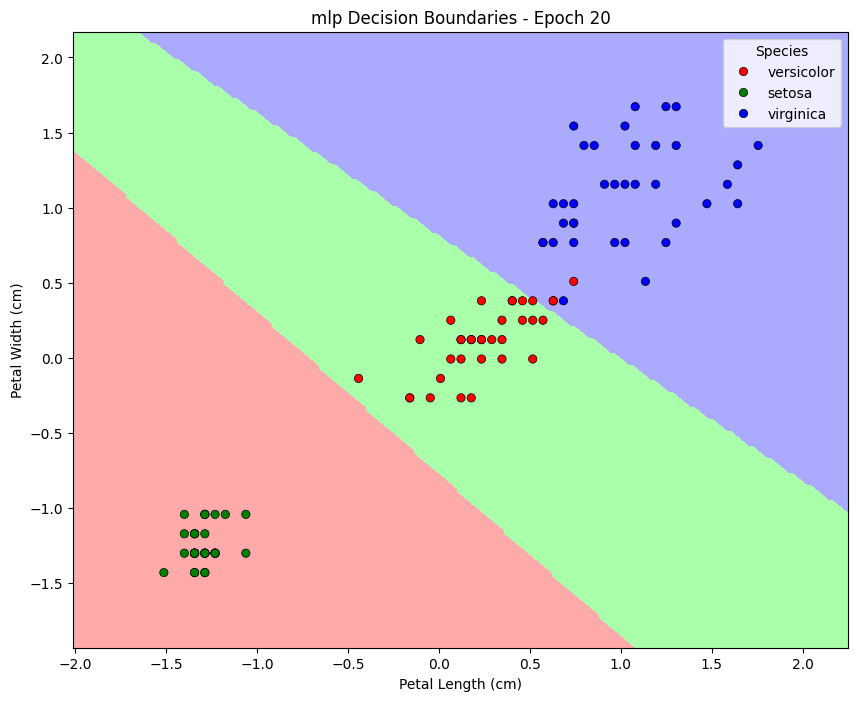

--- Epoch 25 ---


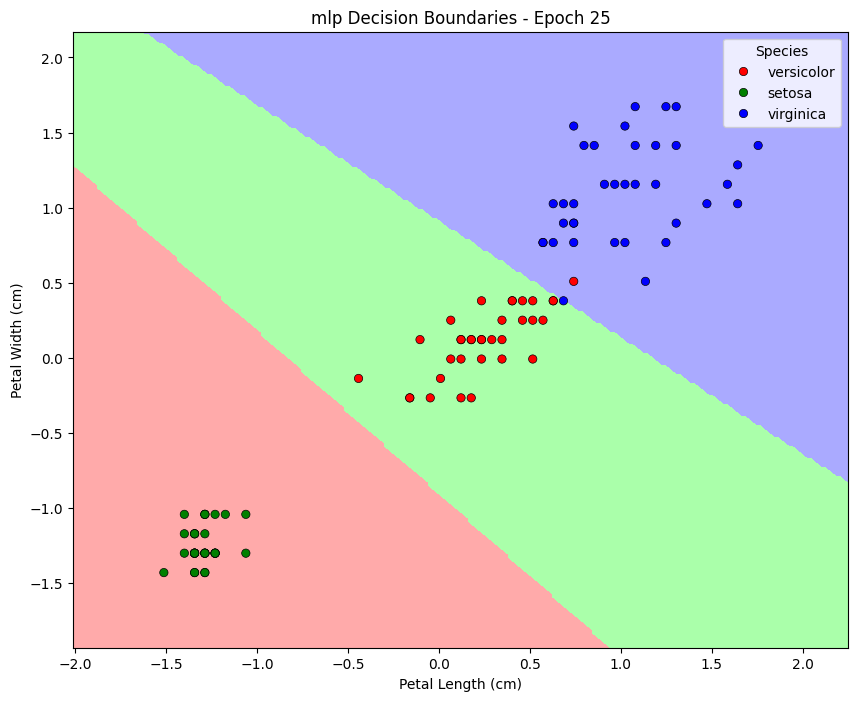

--- Epoch 30 ---


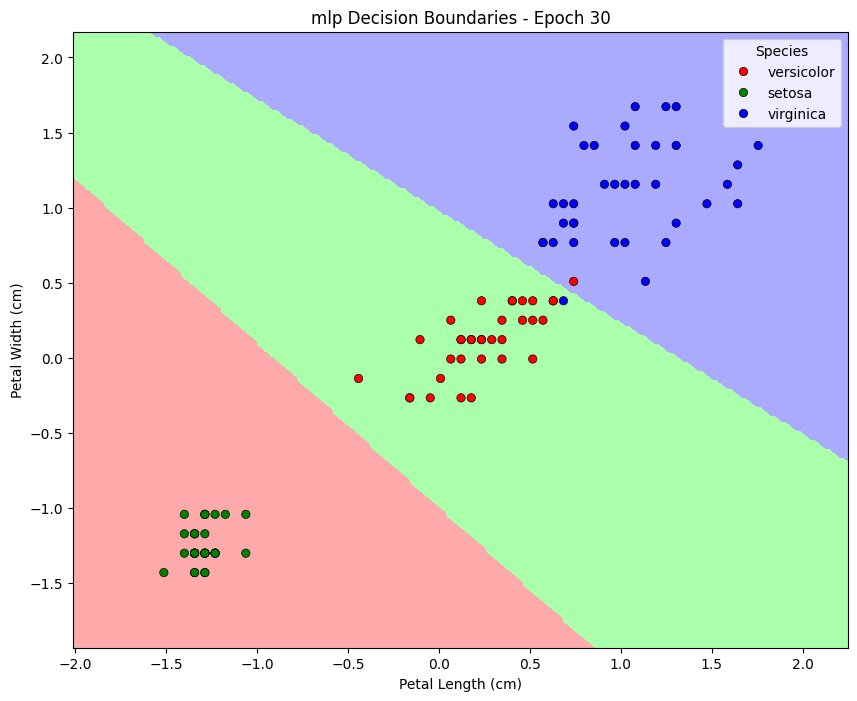

--- Epoch 35 ---


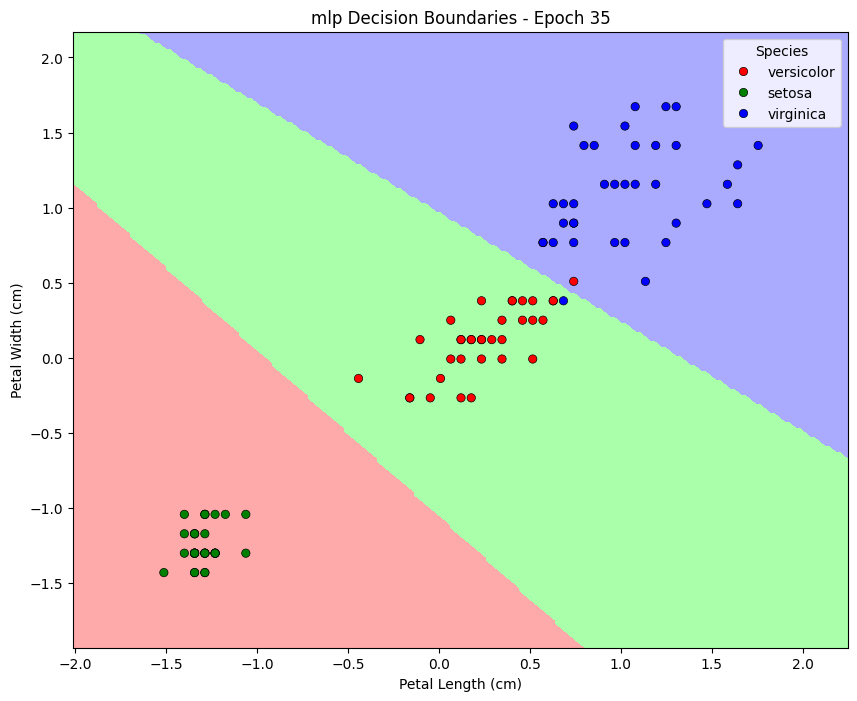

--- Epoch 40 ---


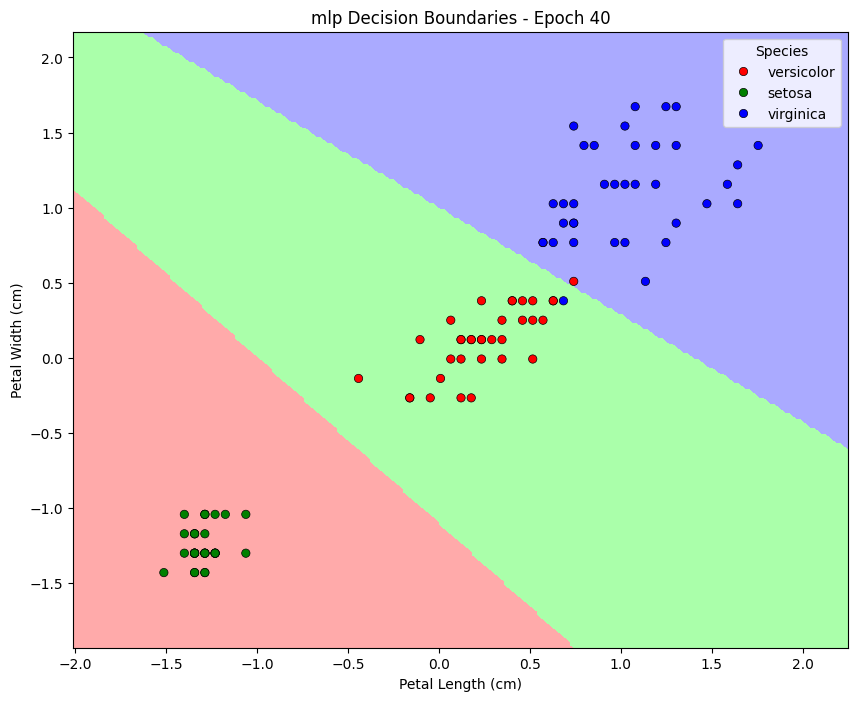

--- Epoch 45 ---


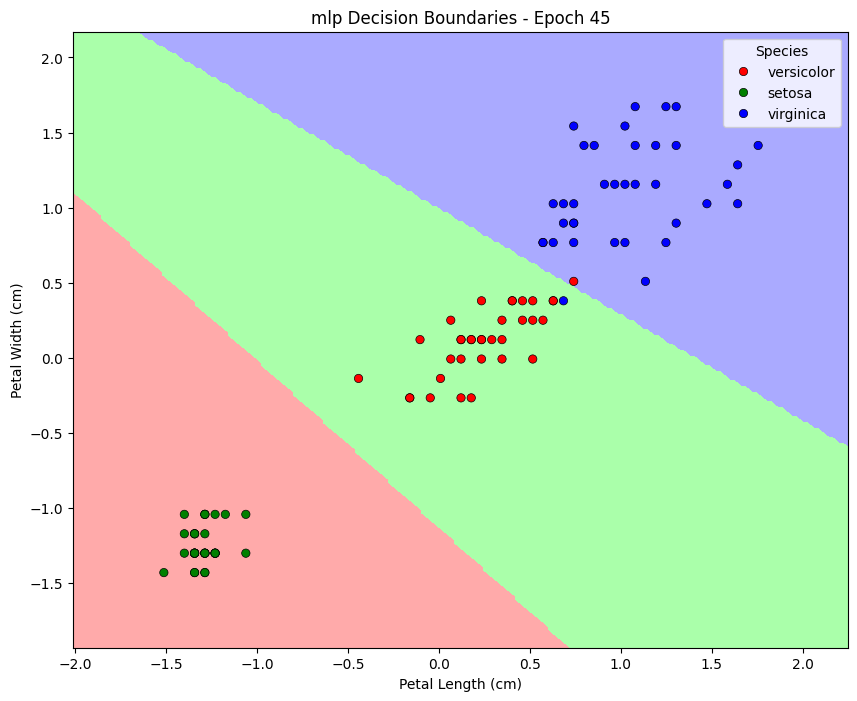

--- Epoch 50 ---


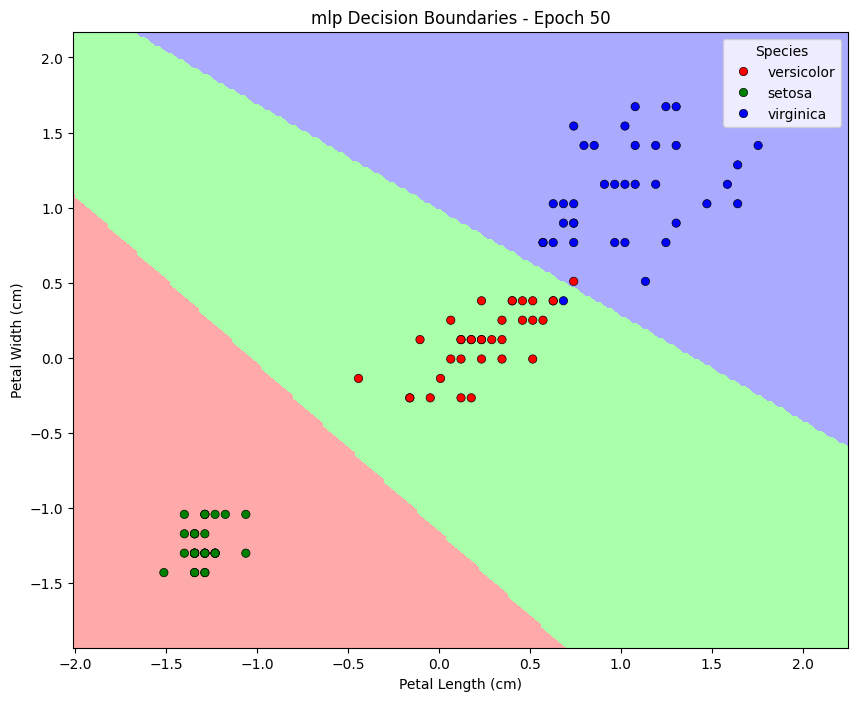

--- Epoch 55 ---


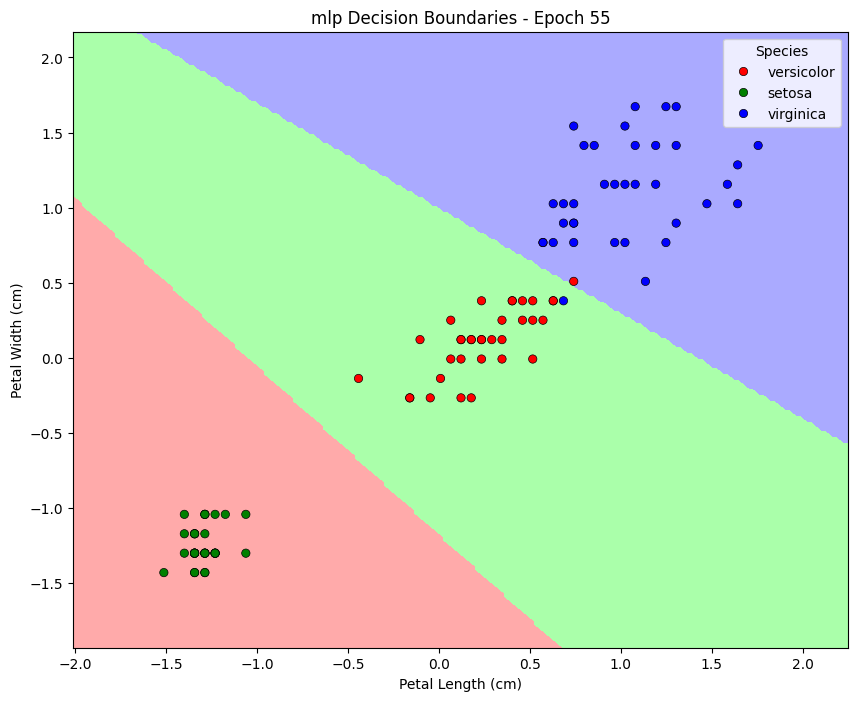

--- Epoch 60 ---


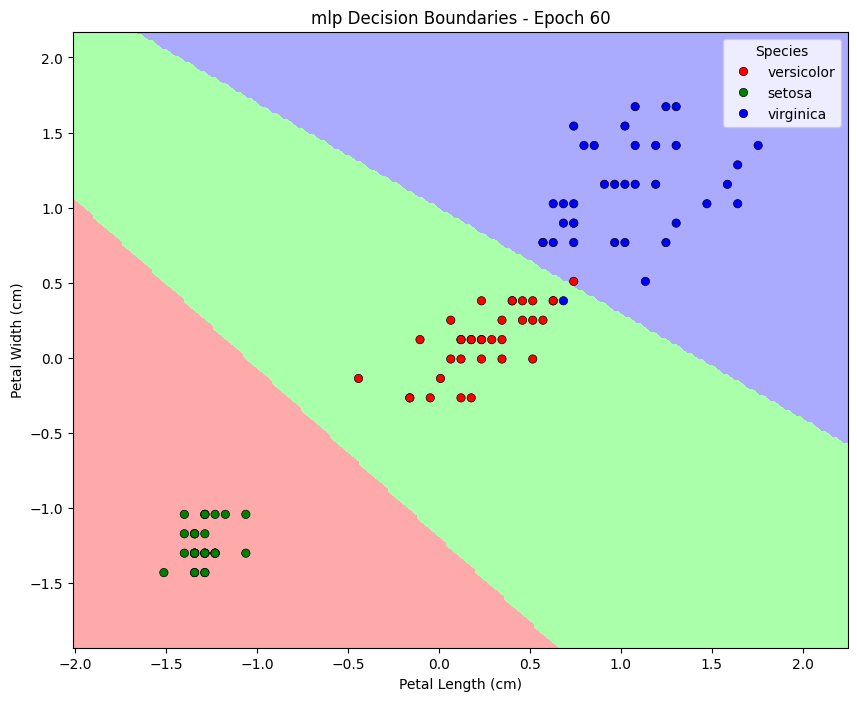

--- Epoch 65 ---


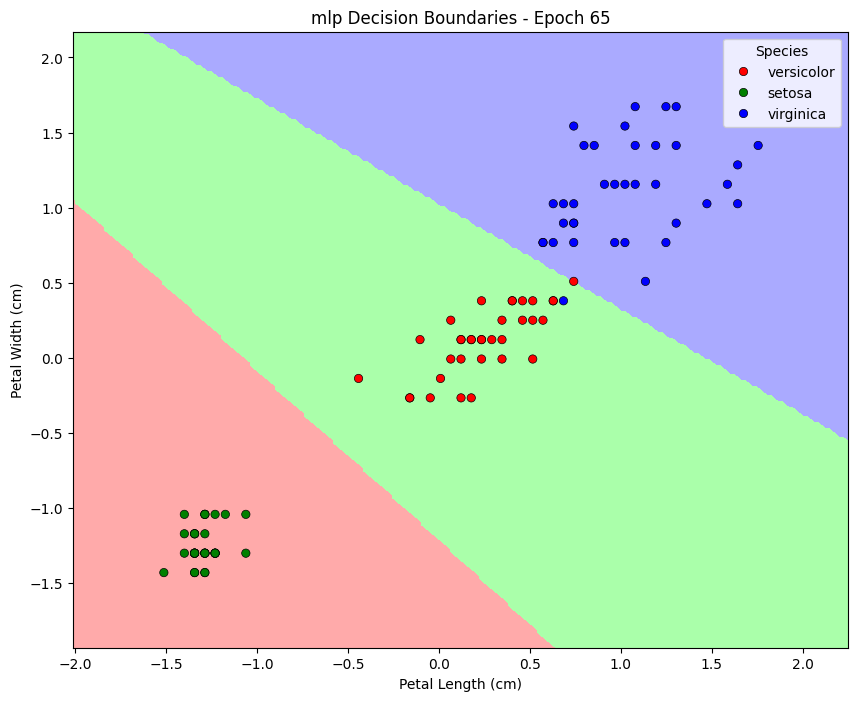

--- Epoch 70 ---


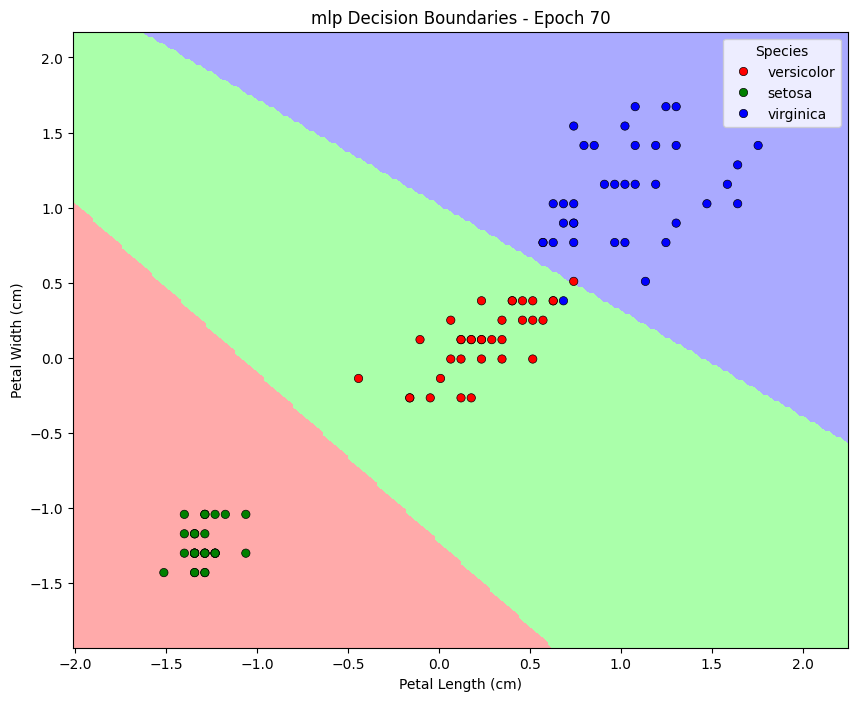

--- Epoch 75 ---


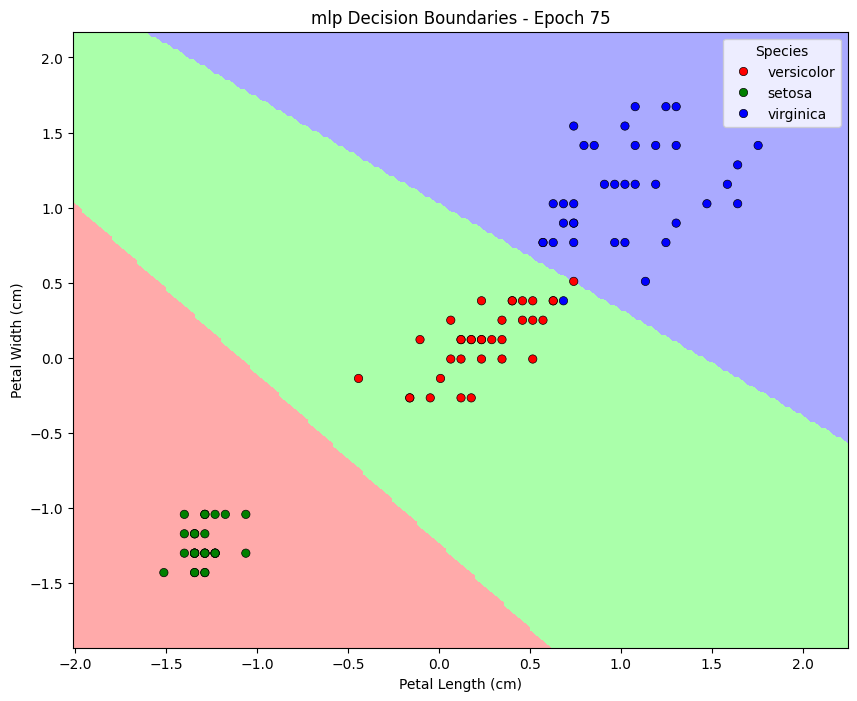

--- Epoch 80 ---


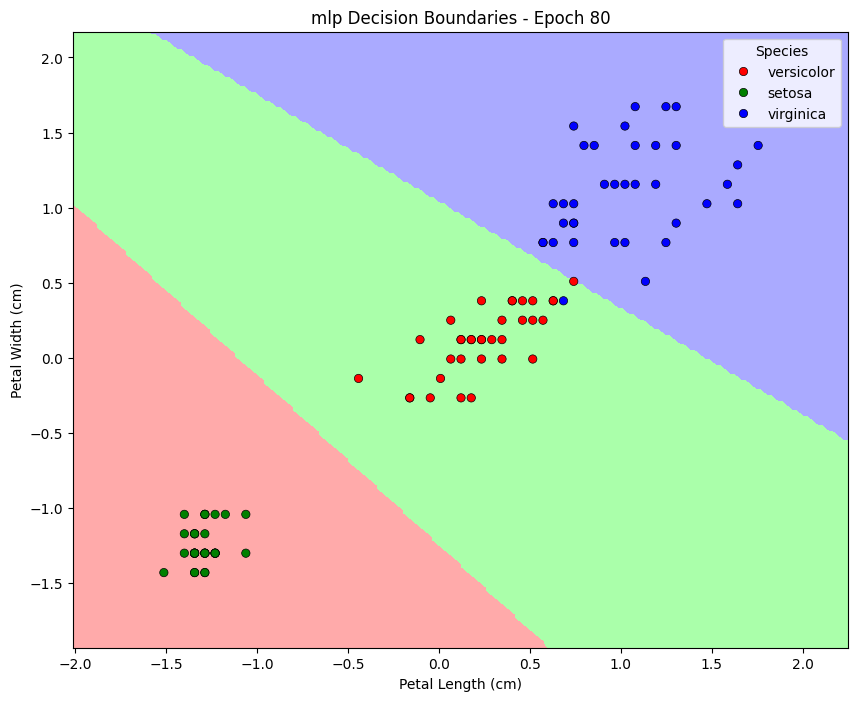

--- Epoch 85 ---


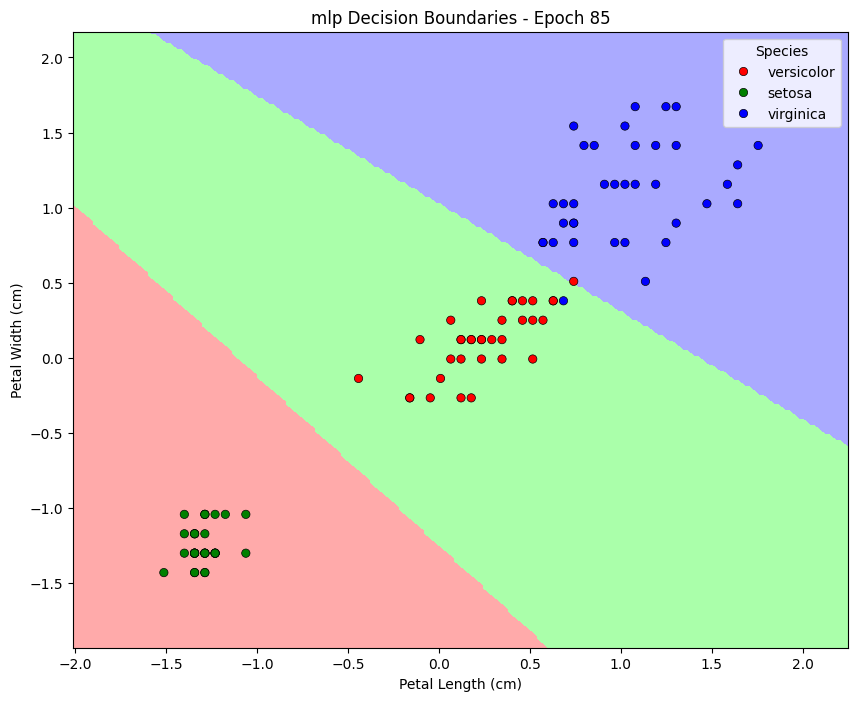

--- Epoch 90 ---


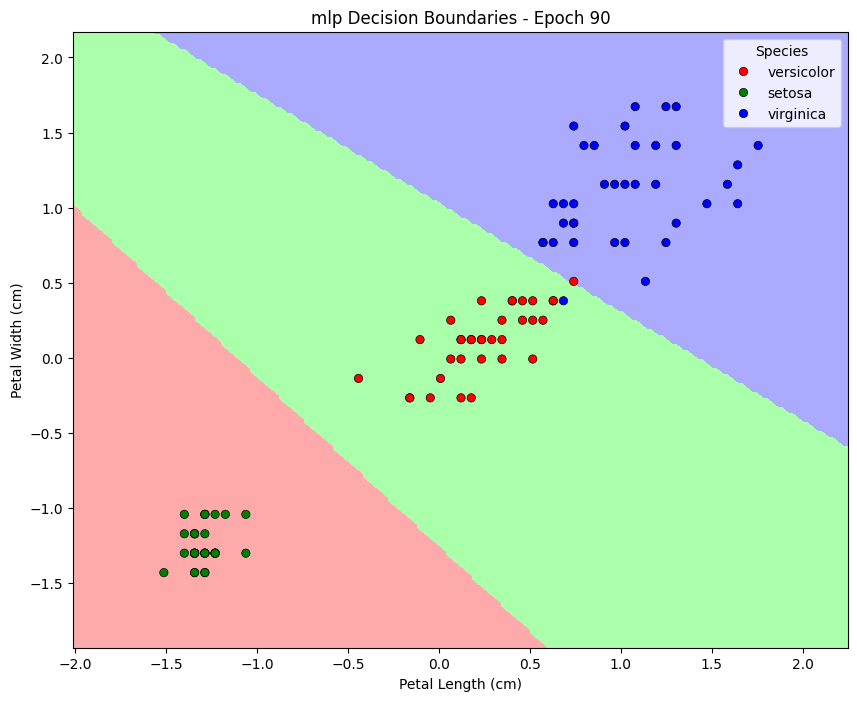

--- Epoch 95 ---


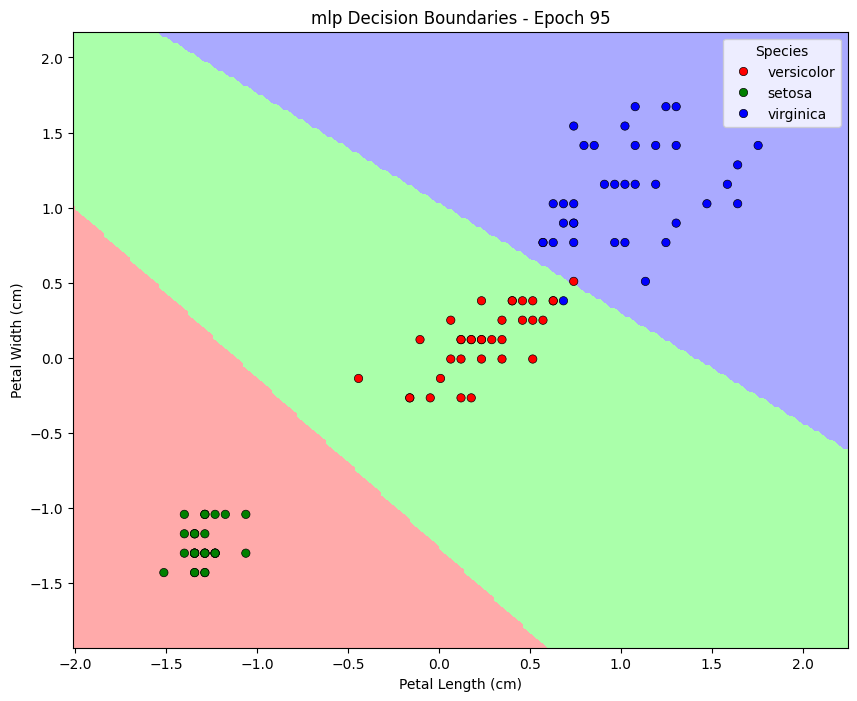

--- Epoch 100 ---


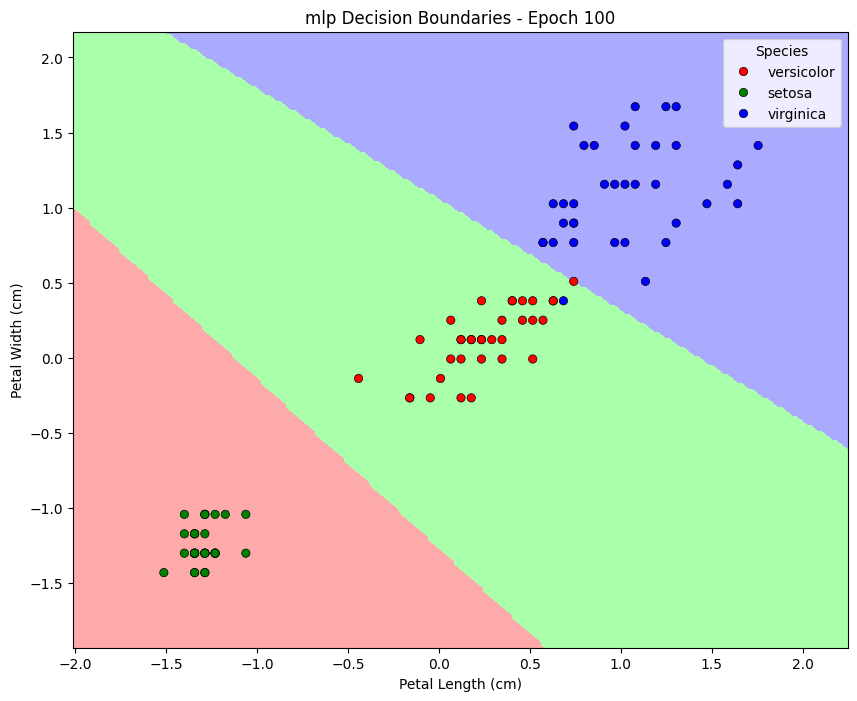

--- Epoch 105 ---


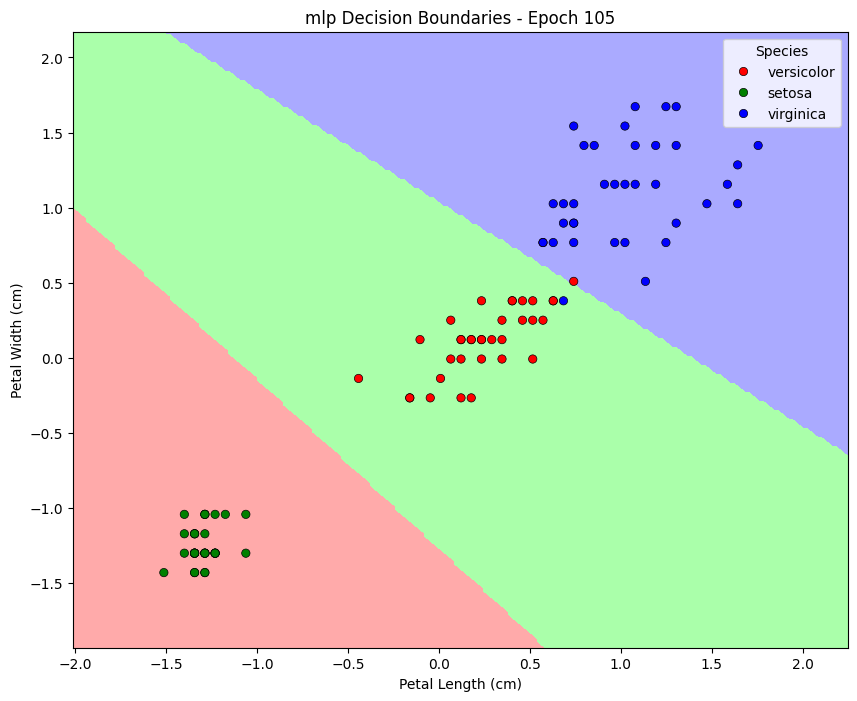

--- Epoch 110 ---


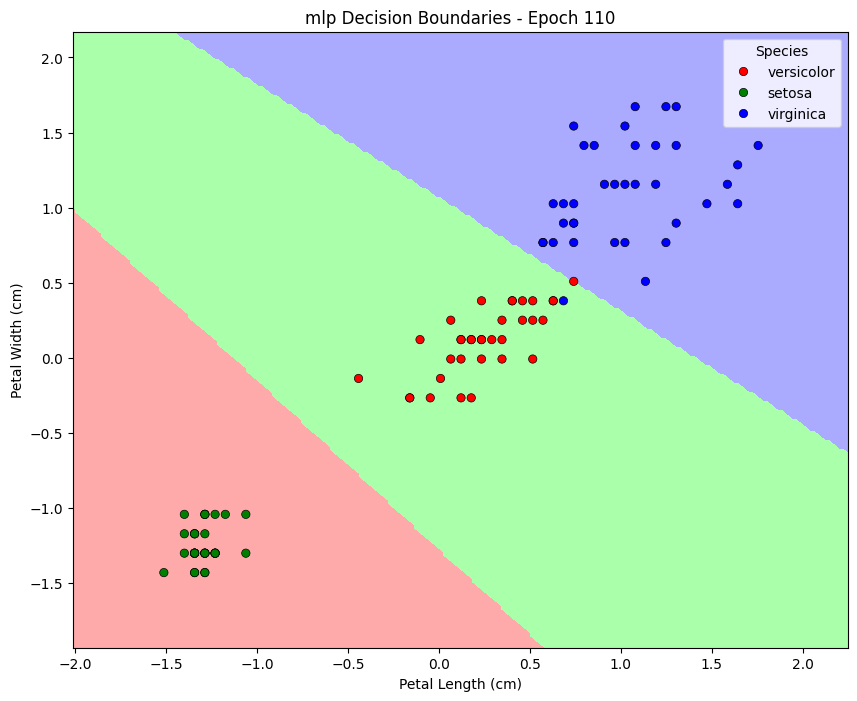

--- Epoch 115 ---


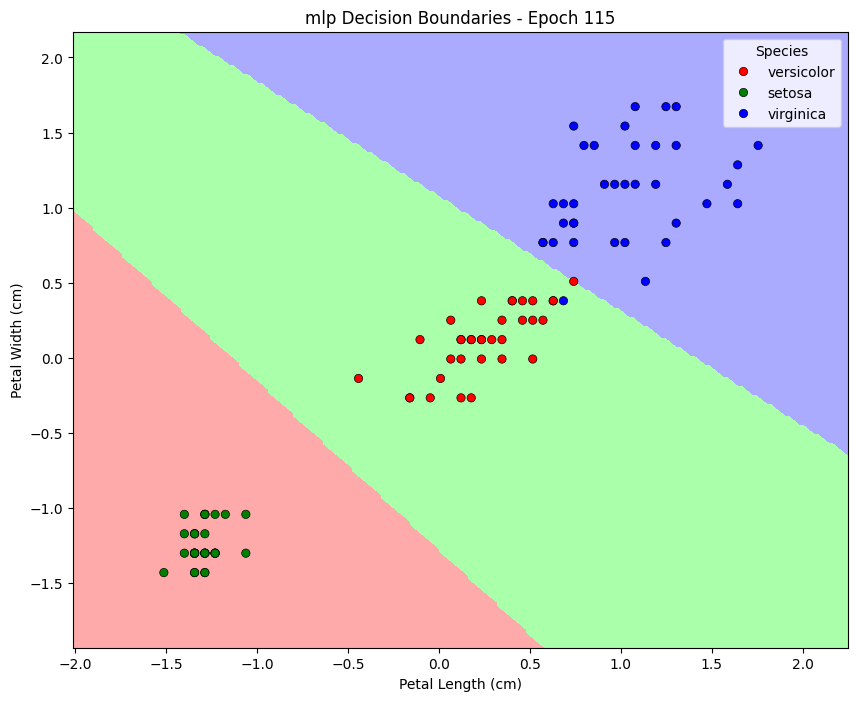

--- Epoch 120 ---


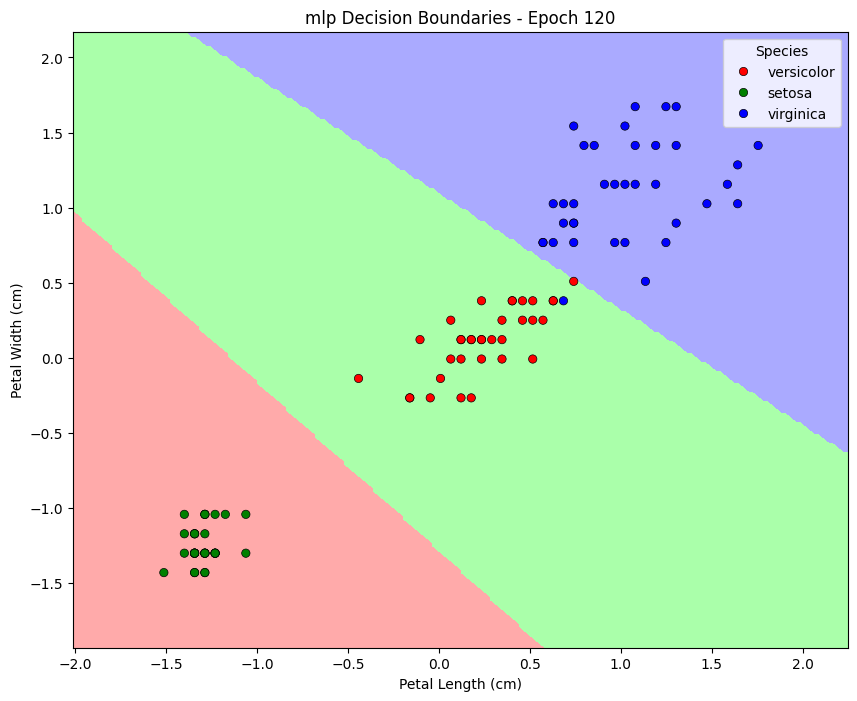

--- Epoch 125 ---


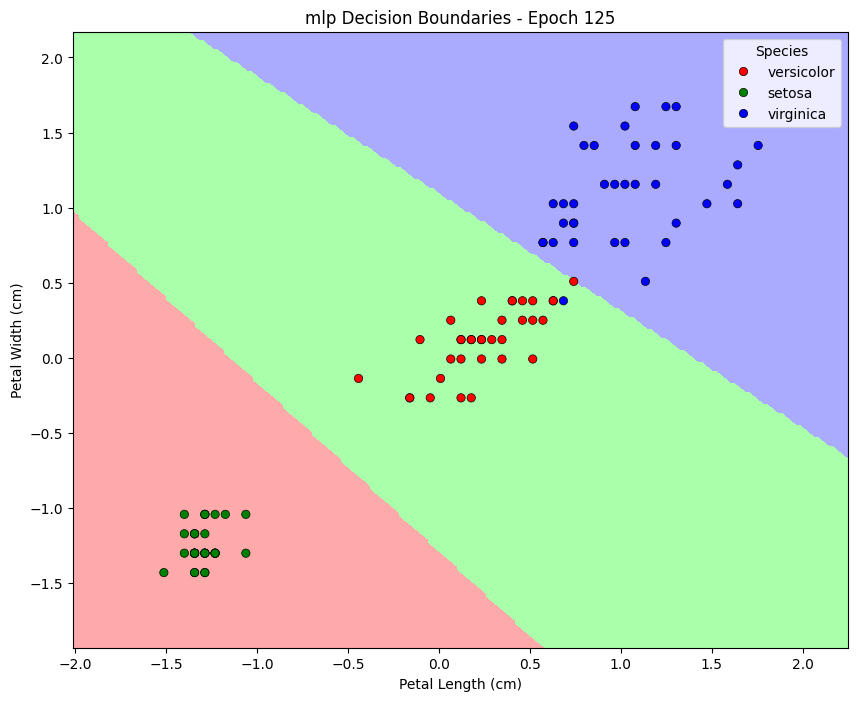

--- Epoch 130 ---


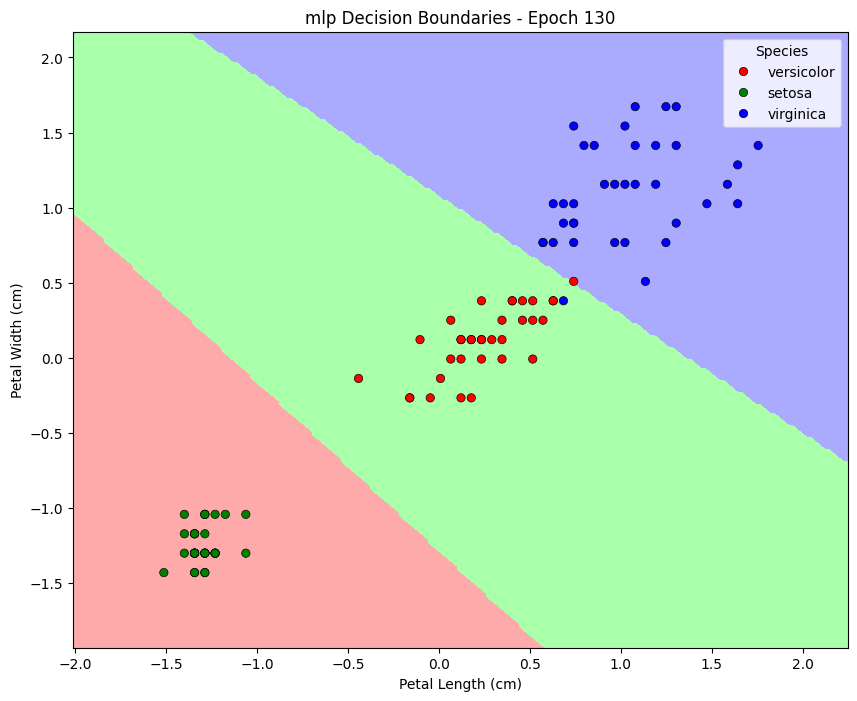

--- Epoch 135 ---


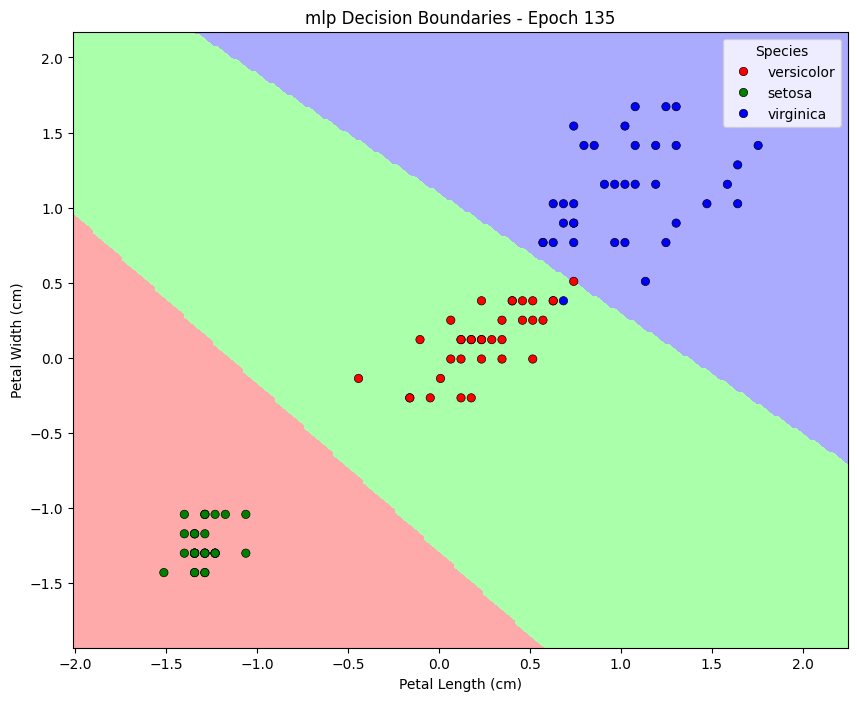

--- Epoch 140 ---


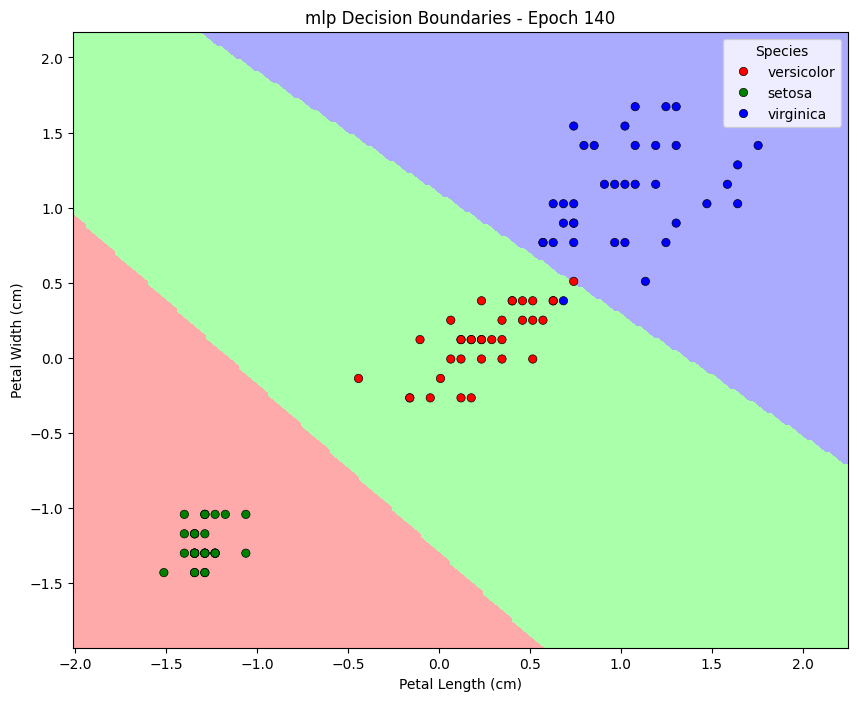

--- Epoch 145 ---


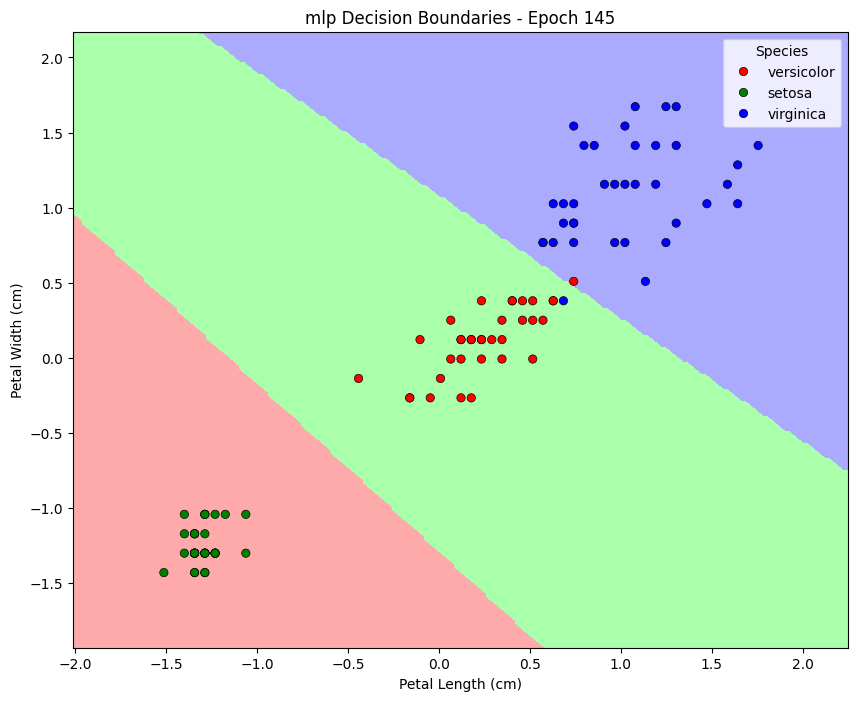

--- Epoch 150 ---


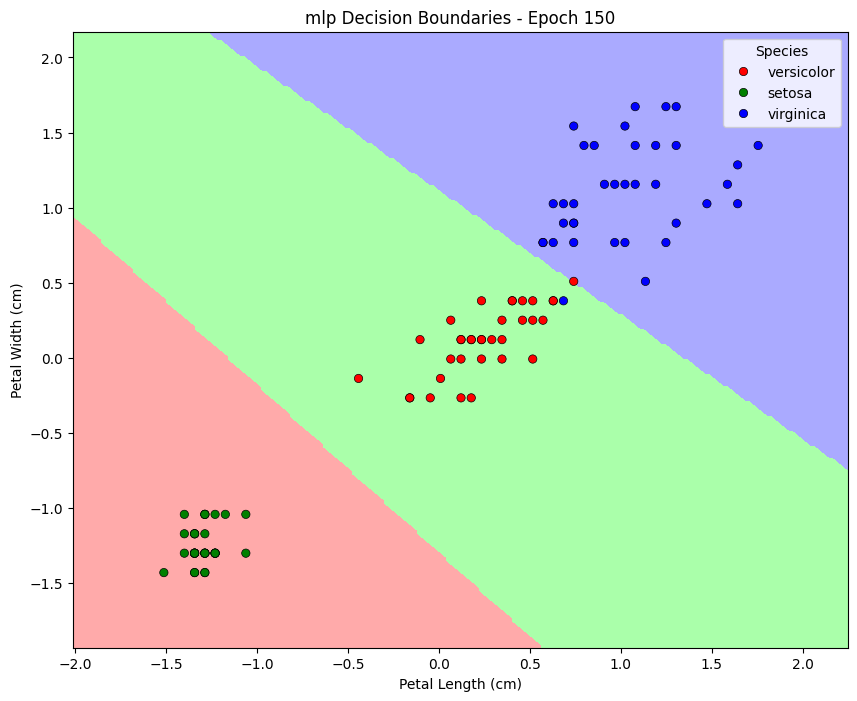

--- Epoch 155 ---


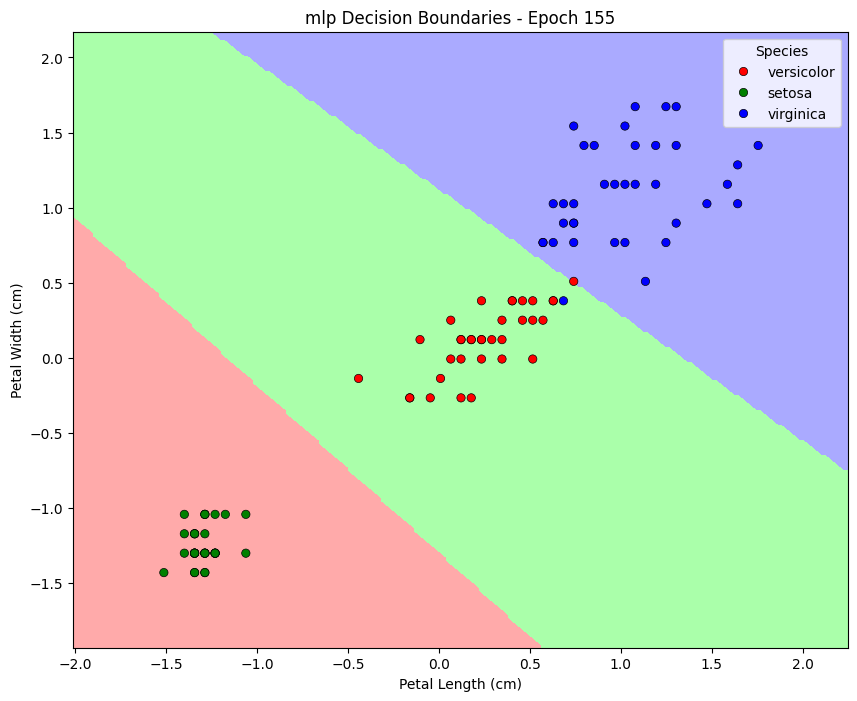

--- Epoch 160 ---


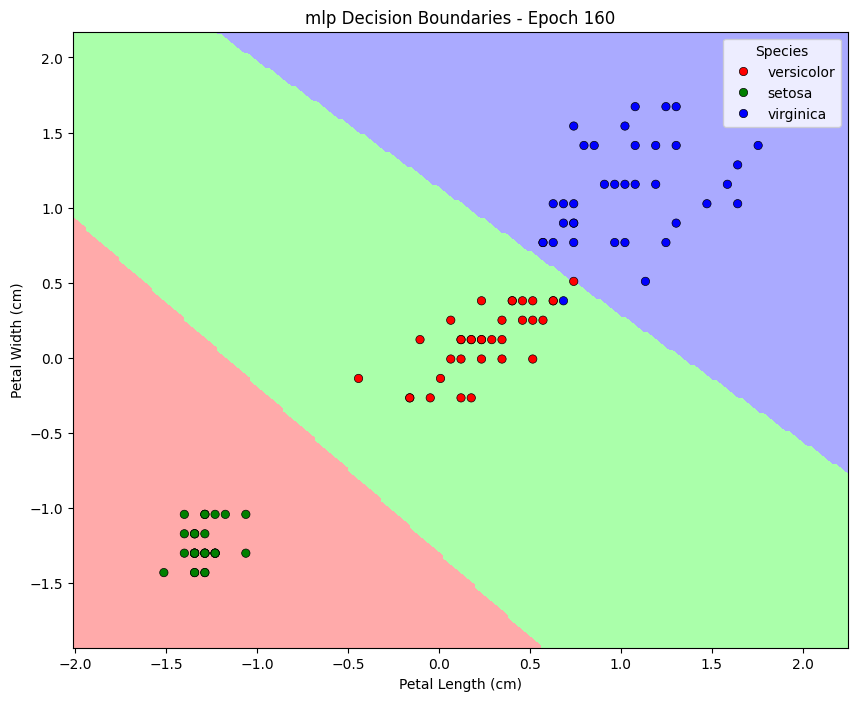

--- Epoch 165 ---


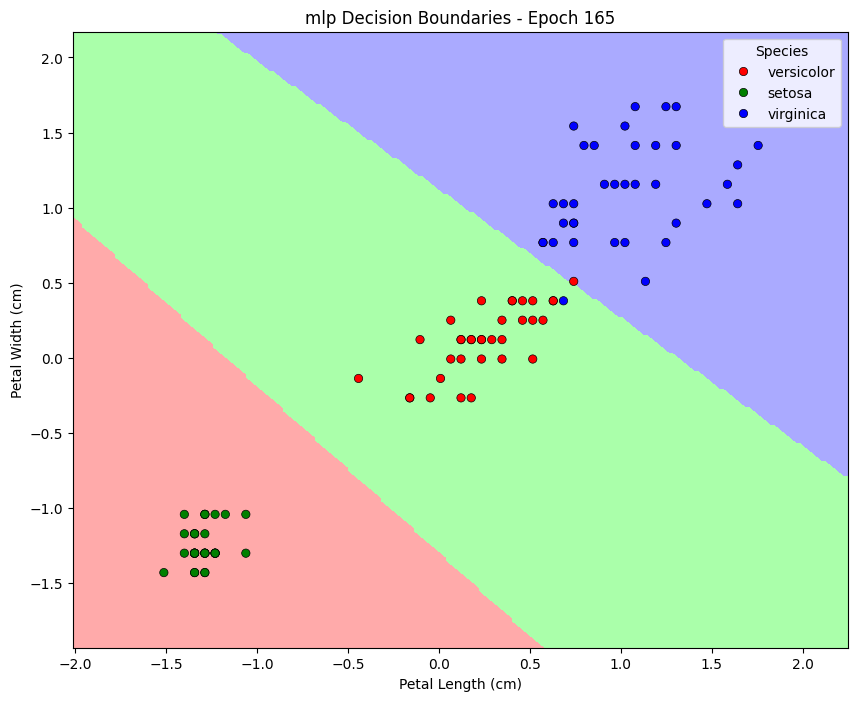

--- Epoch 170 ---


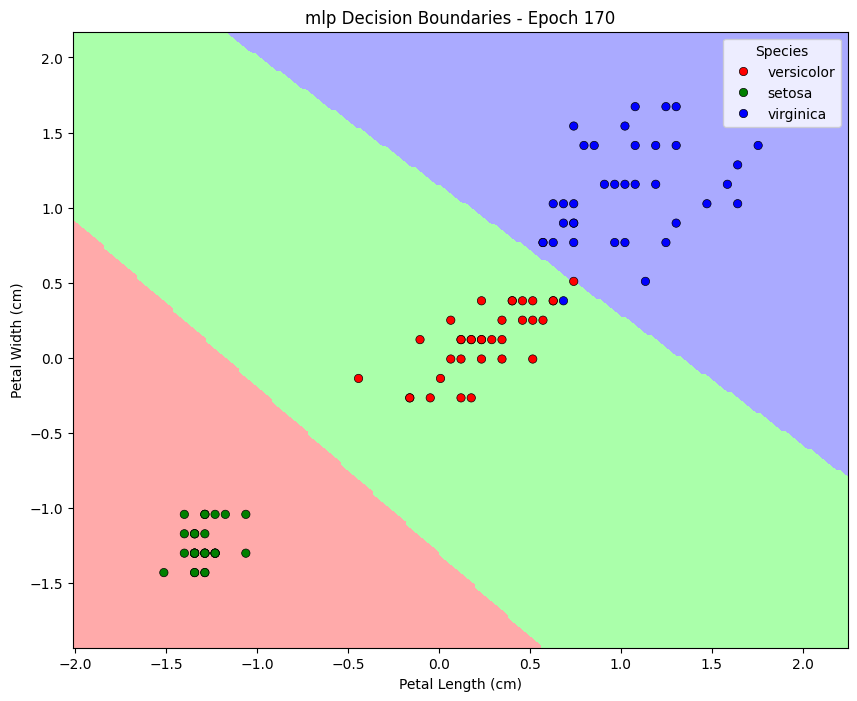

--- Epoch 175 ---


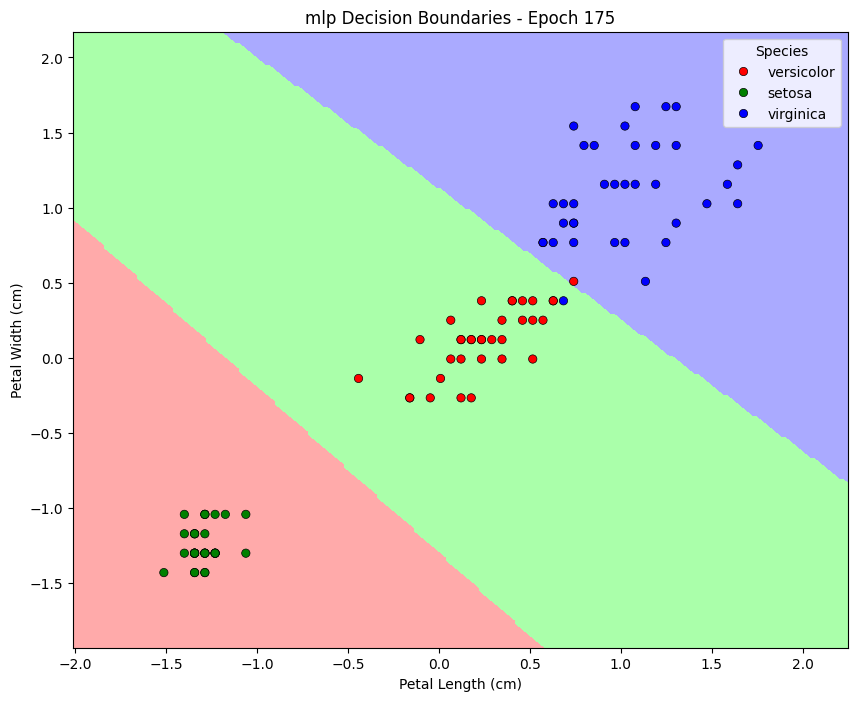

--- Epoch 180 ---


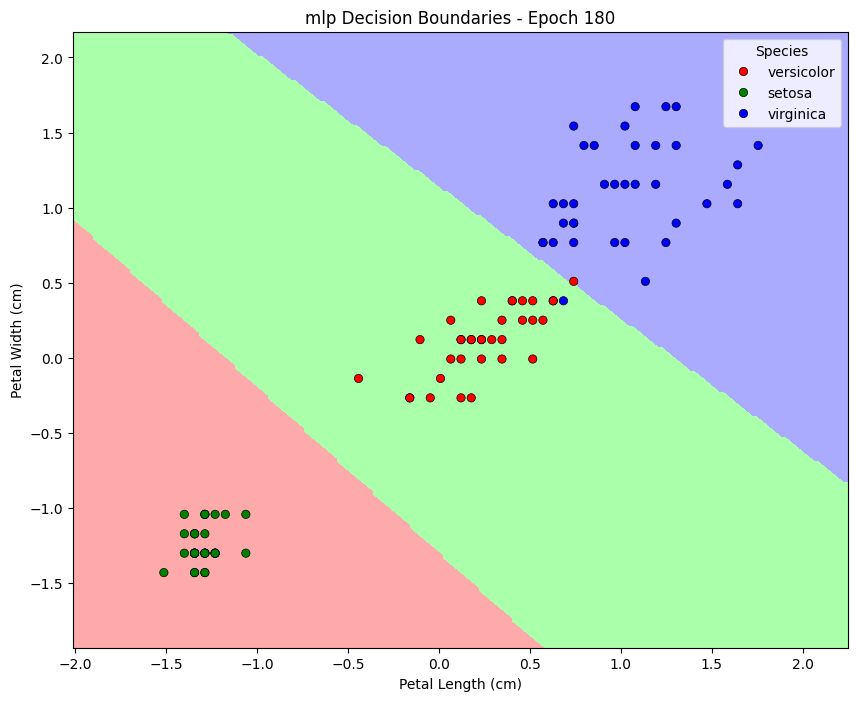

--- Epoch 185 ---


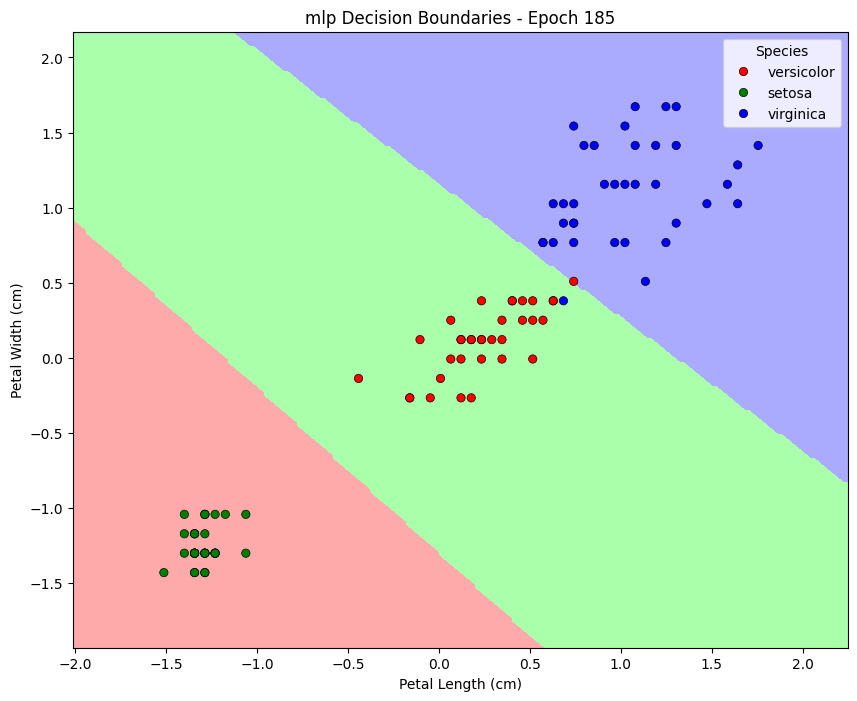

--- Epoch 190 ---


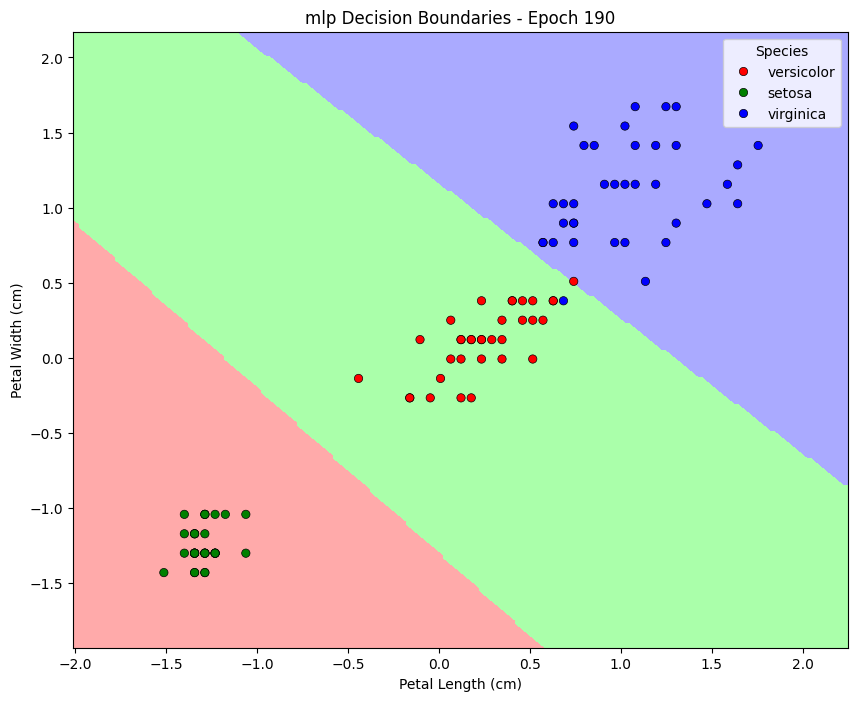

--- Epoch 195 ---


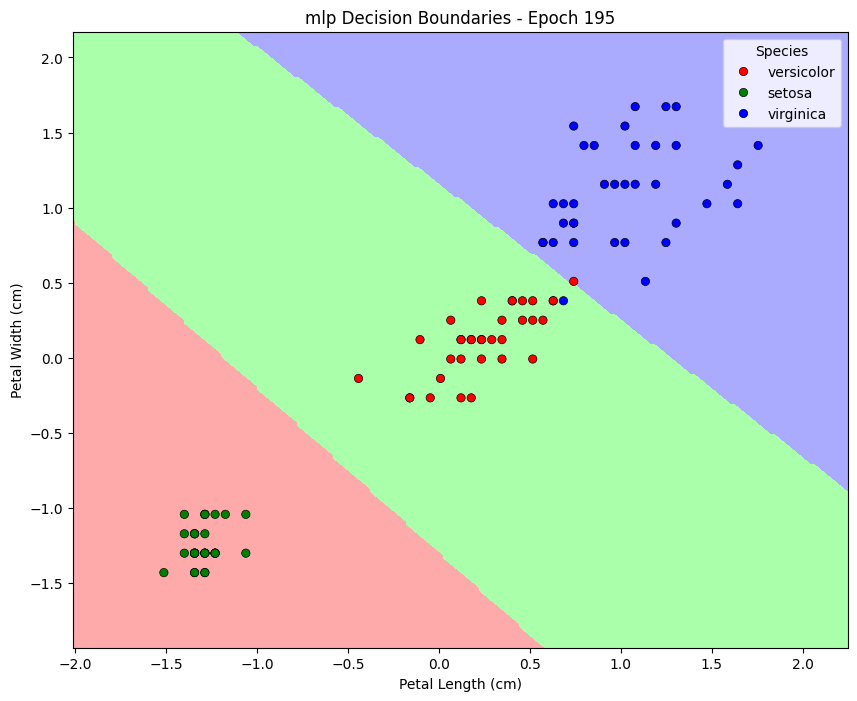

--- Epoch 200 ---


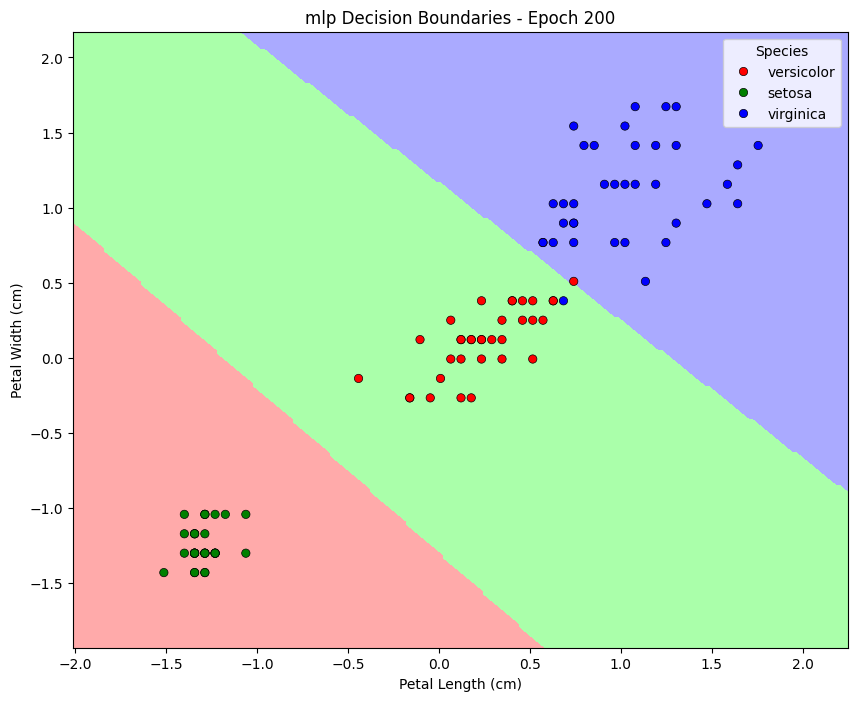

--- 'FROM SCRATCH' MLP TEST REPORT ---


```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45

```


Confusion Matrix:


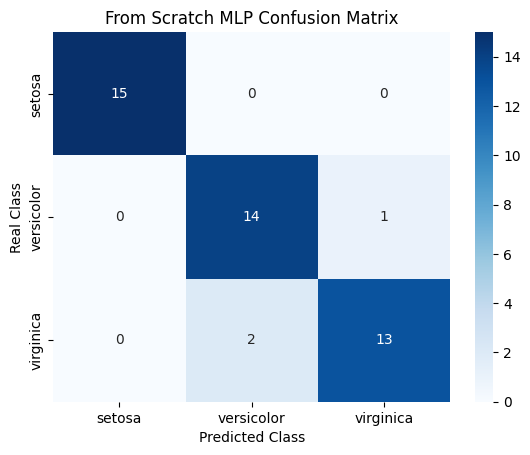

In [126]:
# This Hyperparameter settings are good for a start, you can experiment more in the bonus part.
mlp_scratch = MLPClassifierFromScratch(n_hidden=10, learning_rate=0.01, n_iters=200, random_state=42)

# Train the model with 2-feature training data
# (We use 2 features to be able to draw decision boundaries)
mlp_scratch.fit(X_train_2f_scaled, y_train, plot_every=5)

# Make predictions on the test set
y_pred_mlp_scratch = mlp_scratch.predict(X_test_2f_scaled)

# --- EVALUATION ---

print("--- 'FROM SCRATCH' MLP TEST REPORT ---")
report = classification_report(y_test, y_pred_mlp_scratch, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_mlp_scratch)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted Class')
plt.ylabel('Real Class')
plt.title('From Scratch MLP Confusion Matrix')
plt.show()

### MLPClassifierFromScratch Test Accuracies for Different Hyperparameters

| Hidden Neurons | Learning Rate | Epochs | Test Accuracy |
|:-------------:|:-------------:|:------:|:-------------:|
| 10            | 0.1           | 7500   | 0.91          |
| 10            | 0.01          | 7500   | 0.93          |
| 20            | 0.1           | 10000  | 0.91          |
| 20            | 0.01          | 10000  | 0.93          |
| 20            | 0.01          | 10000  | 0.91          |

This table summarizes the test accuracies achieved by the custom MLP model with different numbers of hidden neurons, learning rates, and training epochs. The results show that a lower learning rate (0.01) generally leads to higher accuracy, especially with more training epochs and hidden neurons. However, increasing the number of hidden neurons does not always guarantee better performance, highlighting the importance of tuning both the learning rate and network size.

In [128]:
print(f"X train shape that use in Part 3: {X_train_full.shape}")
print(f"X train shape that use in Part 3: {y_train.shape}")

X train shape that use in Part 3: (105, 4)
X train shape that use in Part 3: (105,)


## Part 3: Library Baselines

### Scikit-learn Perceptron Model: Detailed Explanation and Results

In this section, we use scikit-learn's `Perceptron` model to classify the Iris dataset. The process involves several key steps:

**1. Pipeline Construction and Grid Search**
- A `Pipeline` is created to streamline preprocessing and model training. It includes:
  - `StandardScaler`: Standardizes features by removing the mean and scaling to unit variance.
  - `SelectKBest(f_classif)`: Selects the top k features based on ANOVA F-value.
  - `Perceptron`: A linear classifier using the perceptron algorithm.
- `GridSearchCV` is used to perform an exhaustive search over specified hyperparameters:
  - `selector__k`: Number of features to select (2, 3, or 4).
  - `classifier__eta0`: Learning rate for the perceptron (various values).
- The grid search uses 5-fold cross-validation to find the best combination of hyperparameters.

**2. Best Model and Feature Selection**
- After fitting, the best model is selected based on cross-validation performance.
- The selected features are identified, showing which input variables are most informative for the classification task.

**3. Model Evaluation**
- The best model is evaluated on the test set.
- The following metrics are reported:
  - **Classification Report**: Includes precision, recall, f1-score, and support for each class.
  - **Confusion Matrix**: Visualizes the number of correct and incorrect predictions for each class.

**Interpretation of Results:**
- The **best parameters** found by grid search indicate the optimal number of features and learning rate for this dataset.
- The **selected features** highlight which measurements (e.g., petal length, petal width) are most important for distinguishing between Iris species.
- The **classification report** provides a detailed breakdown of the model's performance for each class:
  - *Precision*: How many selected items are relevant.
  - *Recall*: How many relevant items are selected.
  - *F1-score*: Harmonic mean of precision and recall.
- The **confusion matrix** helps identify which classes are most often confused by the model.

**Summary Table Example:**

| Parameter           | Value(s) Tested         |
|---------------------|------------------------|
| selector__k         | 2, 3, 4                
| classifier__eta0    | 0.001, 0.01, 0.05, 0.1, 0.2, 0.3 |
| Selected Features   | (see output)           |

**Conclusion:**
- The scikit-learn Perceptron, combined with feature selection and scaling, provides a strong baseline for multi-class classification on the Iris dataset.
- Hyperparameter tuning and feature selection significantly impact model performance.
- The confusion matrix and classification report offer valuable insights into the strengths and weaknesses of the model.

*Refer to the code output above for the exact best parameters, selected features, and detailed performance metrics.*

--- Part 3: Scikit-learn Perceptron Model ---
Fitting 5 folds for each of 18 candidates, totalling 90 fits

--- Perceptron results ---
Best parameters:  {'classifier__eta0': 0.05, 'selector__k': 4}
Selected best features (4): ['sepal length (cm)' 'sepal width (cm)' 'petal length (cm)'
 'petal width (cm)']

Test Report:

--- Perceptron results ---
Best parameters:  {'classifier__eta0': 0.05, 'selector__k': 4}
Selected best features (4): ['sepal length (cm)' 'sepal width (cm)' 'petal length (cm)'
 'petal width (cm)']

Test Report:


```
              precision    recall  f1-score   support

      setosa       0.88      1.00      0.94        15
  versicolor       0.65      0.87      0.74        15
   virginica       1.00      0.53      0.70        15

    accuracy                           0.80        45
   macro avg       0.84      0.80      0.79        45
weighted avg       0.84      0.80      0.79        45

```

Confusion Matrix:


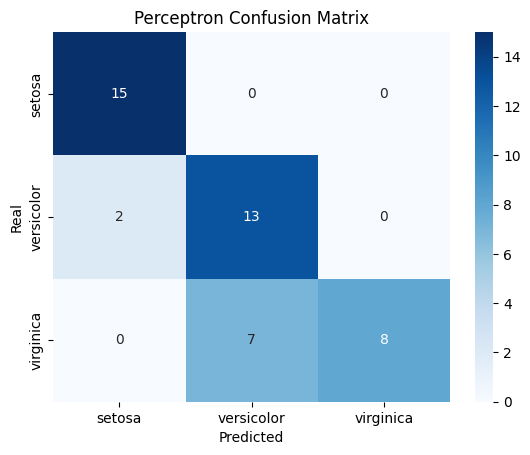

In [129]:
# --- PART 3 ---

print("--- Part 3: Scikit-learn Perceptron Model ---")

# Pipeline ve GridSearchCV
pipe_perceptron = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('classifier', Perceptron(random_state=42, max_iter=2000))
])
param_grid_perceptron = {
    'selector__k': [2, 3, 4],
    'classifier__eta0': [0.001, 0.01, 0.05, 0.1, 0.2, 0.3]
}
grid_search_perceptron = GridSearchCV(pipe_perceptron, param_grid_perceptron, cv=5, verbose=1, n_jobs=-1)
grid_search_perceptron.fit(X_train_full, y_train)

# Take the best model from grid search
best_perceptron = grid_search_perceptron.best_estimator_

# --- Feature Selection ---
# Accessing the 'selector' step of the best model
selector = best_perceptron.named_steps['selector']
# Getting the indices of the selected features
selected_indices = selector.get_support(indices=True)
# Getting the feature names corresponding to these indices
feature_names = np.array(iris.feature_names)
selected_features = feature_names[selected_indices]

print("\n--- Perceptron results ---")
print("Best parameters: ", grid_search_perceptron.best_params_)
print(f"Selected best features ({len(selected_features)}): {selected_features}")

# Test performance (classification_report and confusion_matrix)
y_pred_perceptron_lib = best_perceptron.predict(X_test_full)
print("\nTest Report:")
report = classification_report(y_test, y_pred_perceptron_lib, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred_perceptron_lib)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Real')
plt.title('Perceptron Confusion Matrix')
plt.show()

# Analysis of an MLPClassifier Model with Scikit-learn Pipeline and GridSearchCV

This document provides a detailed breakdown of a Python script designed to build, tune, and evaluate a Multi-Layer Perceptron (MLP) classifier. The workflow leverages Scikit-learn's `Pipeline` to chain preprocessing and modeling steps, and `GridSearchCV` to systematically find the optimal set of hyperparameters.

---


The script is logically divided into three main sections:
1.  **Pipeline Construction**: A machine learning pipeline is defined to sequentially perform feature scaling (`StandardScaler`), feature selection (`SelectKBest`), and classification (`MLPClassifier`).
2.  **Hyperparameter Tuning**: `GridSearchCV` is configured to explore a predefined grid of parameters for both the feature selection and classifier steps to identify the best-performing combination.
3.  **Model Evaluation**: After the best model is identified through training, its performance is assessed on an independent test dataset. The evaluation is presented through a `classification_report` and a visualized `confusion_matrix`.

---



--- Part 3: Scikit-learn MLPClassifier Model ---
Fitting 5 folds for each of 108 candidates, totalling 540 fits

--- MLPClassifier Results ---
Best parameters:  {'classifier__activation': 'tanh', 'classifier__hidden_layer_sizes': (20,), 'classifier__learning_rate_init': 0.05, 'selector__k': 3}
Selected best features (3): ['sepal length (cm)' 'petal length (cm)' 'petal width (cm)']

Test Report:

--- MLPClassifier Results ---
Best parameters:  {'classifier__activation': 'tanh', 'classifier__hidden_layer_sizes': (20,), 'classifier__learning_rate_init': 0.05, 'selector__k': 3}
Selected best features (3): ['sepal length (cm)' 'petal length (cm)' 'petal width (cm)']

Test Report:


```
              precision    recall  f1-score   support

      setosa       0.88      1.00      0.94        15
  versicolor       0.80      0.53      0.64        15
   virginica       0.72      0.87      0.79        15

    accuracy                           0.80        45
   macro avg       0.80      0.80      0.79        45
weighted avg       0.80      0.80      0.79        45

```

Confusion Matrix:


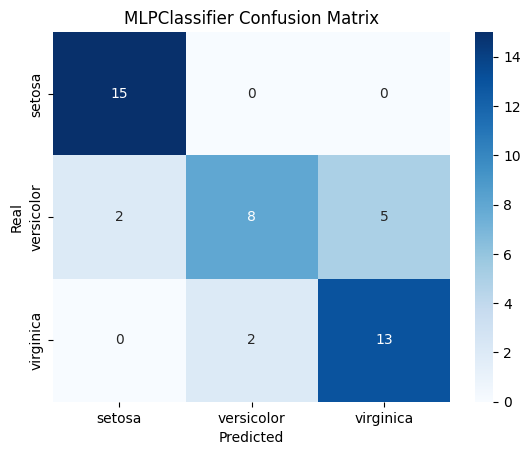

In [130]:
print("\n\n--- Part 3: Scikit-learn MLPClassifier Model ---")

# Pipeline (solver='sgd' added)
pipe_mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('classifier', MLPClassifier(random_state=42, max_iter=5000, early_stopping=True, solver='sgd')) # <-- This Change for MLPClassifier
])

# GridSearchCV
param_grid_mlp = {
    'selector__k': [2, 3, 4],
    'classifier__hidden_layer_sizes': [(10,), (20,), (10, 5)],
    'classifier__activation': ['tanh', 'relu'],
    'classifier__learning_rate_init': [0.001, 0.01, 0.05, 0.1, 0.2, 0.3]
}
grid_search_mlp = GridSearchCV(pipe_mlp, param_grid_mlp, cv=5, verbose=1, n_jobs=-1)
grid_search_mlp.fit(X_train_full, y_train)

# En iyi modeli al
best_mlp = grid_search_mlp.best_estimator_

# --- Feature Selection ---
selector_mlp = best_mlp.named_steps['selector']
selected_indices_mlp = selector_mlp.get_support(indices=True)
selected_features_mlp = feature_names[selected_indices_mlp]

print("\n--- MLPClassifier Results ---")
print("Best parameters: ", grid_search_mlp.best_params_)
print(f"Selected best features ({len(selected_features_mlp)}): {selected_features_mlp}")

# Test performance (classification_report and confusion_matrix)
y_pred_mlp_lib = best_mlp.predict(X_test_full)
print("\nTest Report:")
report = classification_report(y_test, y_pred_mlp_lib, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))

print("Confusion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred_mlp_lib)
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Real')
plt.title('MLPClassifier Confusion Matrix')
plt.show()

# Scikit-learn Models Test Evaluation

This section of the notebook is dedicated to evaluating the performance of two previously trained models: the **Perceptron** (Single-Layer Perceptron) and the **MLPClassifier** (Multi-Layer Perceptron). The specific models being evaluated are the best-performing ones identified through `GridSearchCV` in the preceding steps. Their generalization ability is now being tested on a dataset they have not seen before (the test set).

---

In [131]:
# ----------------------------------------------------------------------
# Scikit models test evaluation
# ----------------------------------------------------------------------

print("="*50)
print("Scikit-learn Models Test Evaluation")
print("="*50)

# 1. take the best SLP (Perceptron) model and predict on X_test
# grid_search_perceptron variable is assumed to be trained in the previous cell
best_slp_model = grid_search_perceptron.best_estimator_
y_pred_slp_sklearn = best_slp_model.predict(X_test_full) # Original X_test (4 features)

print("\n--- 1. SKLEARN PERCEPTRON (BEST MODEL) TEST REPORT ---")
print(f"Best parameters: {grid_search_perceptron.best_params_}")
report = classification_report(y_test, y_pred_slp_sklearn, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_slp = confusion_matrix(y_test, y_pred_slp_sklearn)
print(cm_slp)

# 2. take the best MLP (MLPClassifier) model and predict on X_test
# grid_search_mlp variable is assumed to be trained in the previous cell
best_mlp_model_sklearn = grid_search_mlp.best_estimator_
y_pred_mlp_sklearn = best_mlp_model_sklearn.predict(X_test_full) # Original X_test (4 features)

print("\n--- 2. SKLEARN MLPCLASSIFIER (BEST MODEL) TEST REPORT ---")
print(f"Best parameters: {grid_search_mlp.best_params_}")
report = classification_report(y_test, y_pred_mlp_sklearn, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred_mlp_sklearn)
print(cm_mlp)

Scikit-learn Models Test Evaluation

--- 1. SKLEARN PERCEPTRON (BEST MODEL) TEST REPORT ---
Best parameters: {'classifier__eta0': 0.05, 'selector__k': 4}


```
              precision    recall  f1-score   support

      setosa       0.88      1.00      0.94        15
  versicolor       0.65      0.87      0.74        15
   virginica       1.00      0.53      0.70        15

    accuracy                           0.80        45
   macro avg       0.84      0.80      0.79        45
weighted avg       0.84      0.80      0.79        45

```

Confusion Matrix:
[[15  0  0]
 [ 2 13  0]
 [ 0  7  8]]

--- 2. SKLEARN MLPCLASSIFIER (BEST MODEL) TEST REPORT ---
Best parameters: {'classifier__activation': 'tanh', 'classifier__hidden_layer_sizes': (20,), 'classifier__learning_rate_init': 0.05, 'selector__k': 3}


```
              precision    recall  f1-score   support

      setosa       0.88      1.00      0.94        15
  versicolor       0.80      0.53      0.64        15
   virginica       0.72      0.87      0.79        15

    accuracy                           0.80        45
   macro avg       0.80      0.80      0.79        45
weighted avg       0.80      0.80      0.79        45

```

Confusion Matrix:
[[15  0  0]
 [ 2  8  5]
 [ 0  2 13]]


# 'From-Scratch' Models Evaluation Code

This script is designed to evaluate the performance of two neural network models that were previously built "from-scratch": a Single-Layer Perceptron (SLP) and a Multi-Layer Perceptron (MLP). Its main goal is to assess how well these custom-coded models generalize to new, unseen test data. To achieve this, the code uses each trained model to make predictions on the test set and then generates standard evaluation metrics. Finally, it displays a detailed `classification_report` and a `confusion_matrix` for both the SLP and MLP models to provide a clear summary of their predictive accuracy.

In [132]:
# ----------------------------------------------------------------------
# Scratch models test evaluation
# ----------------------------------------------------------------------

print("\n" + "="*50)
print("PART 2 - 'FROM-SCRATCH' MODELS TEST EVALUATION")
print("="*50)

# Scratch modells trained with 2 features (X_train_2f),
# So we will evaluate them on X_test_2f
# y_test remains the original 1D labels.

# 1. Scratch SLP model evaluation
# 'slp_ovr' models trained in Part 2 with 2 features
y_pred_slp_scratch = slp_ovr_model.predict(X_test_2f)

print("\n--- 1. 'FROM-SCRATCH' SLP (SLP_OvR) TEST REPORT ---")
report = classification_report(y_test, y_pred_slp_scratch, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_slp_scratch = confusion_matrix(y_test, y_pred_slp_scratch)
print(cm_slp_scratch)


# 2. Scratch MLP model evaluation
# 'mlp_ovr' model trained in Part 2 with 2 features
#
# -----------------------------------------------------------------
# 
# predict method of 'MLP_OvR' returns (n_samples, n_classes) shape,
# while 'MLPClassifierFromScratch' returns (n_samples,) shape.
# So we need to handle both cases here.


try:
    # if you have trained 'MLP_OvR' (Cell 11) model and named it 'mlp_ovr':
    y_pred_mlp_scratch = mlp_scratch.predict(X_test_2f_scaled)
    
except AttributeError:
    # if you have trained 'MLPClassifierFromScratch' (Cell 10)
    # and named it differently, change the variable name below:
    # y_pred_mlp_scratch = best_mlp_model.predict(X_test_2f)
    print("Error: 'MLP_OvR' model not found.")
    print("Please enter the variable name of your trained model (e.g., 'best_mlp_model').")
    y_pred_mlp_scratch = y_pred_slp_scratch # Temporarily suppress the error


# 'MLP_OvR' (Cell 11) model returns (n_samples, n_classes) shape,
# 'MLPClassifierFromScratch' = (112,) . To be Sure, we check the shape here:
if y_pred_mlp_scratch.ndim > 1:
    y_pred_mlp_scratch = np.argmax(y_pred_mlp_scratch, axis=1)
    



print("\n--- 2. 'SIFIRDAN' MLP (MLP_OvR / MLPClassifierFromScratch) TEST REPORT ---")
report = classification_report(y_test, y_pred_mlp_scratch, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_mlp_scratch = confusion_matrix(y_test, y_pred_mlp_scratch)
print(cm_mlp_scratch)




PART 2 - 'FROM-SCRATCH' MODELS TEST EVALUATION

--- 1. 'FROM-SCRATCH' SLP (SLP_OvR) TEST REPORT ---


```
              precision    recall  f1-score   support

      setosa       1.00      0.93      0.97        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45

```

Confusion Matrix:
[[14  1  0]
 [ 0 14  1]
 [ 0  3 12]]

--- 2. 'SIFIRDAN' MLP (MLP_OvR / MLPClassifierFromScratch) TEST REPORT ---


```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45

```

Confusion Matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]
